# Full inference with merge-candidate OCR grouping

Reuses pipelineWbubbles stages and caches. Agreement < 0.4 or SFX in any OCR source deletes the entire box from final output. Only surviving Magi texts influence contour checks and grouping. Overlapping YOLO candidates are grouped only when at least one has no individual boundary after the normal pass and faint retry. Their matching texts are joined even if a merged outline cannot be found. No merged-outline test or narration/speaker override is added.

Run with godfather.venv. Configure the sequence in the original settings cell. The final cells show candidate groups and grouped text on each page, then export grouped transcripts alongside the original per-box outputs into pipelineContour_outputs.


## 1. Imports and offline execution

Import Torch before Paddle, as required by this environment. Model loading uses local files or the existing local Hugging Face cache.

In [38]:
# Set offline mode before importing Hugging Face model loaders.
import os
os.environ['HF_HUB_OFFLINE'] = '1'
os.environ['TRANSFORMERS_OFFLINE'] = '1'
os.environ['PADDLE_PDX_DISABLE_MODEL_SOURCE_CHECK'] = 'True'
import torch  # Must precede Paddle on this Windows installation.
import paddle
import gc
import copy
import hashlib
import json
import sys
import unicodedata
from datetime import datetime, timezone
from importlib.metadata import version
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.patches as patches
import ipywidgets as widgets
from IPython.display import display
from PIL import Image
from transformers import AutoModel, AutoConfig, AutoTokenizer
from paddleocr import PaddleOCR

print('Python:', sys.executable)
print('Torch:', torch.__version__, '| Paddle:', paddle.__version__)

import importlib.util
import inspect
import types
from scipy.optimize import linear_sum_assignment

# Load a local Python file under a unique module name: avoid collisions with other config/model files.
def load_local_module(name, path):
    spec = importlib.util.spec_from_file_location(name, path)
    module = importlib.util.module_from_spec(spec)
    spec.loader.exec_module(module)
    return module


Python: c:\Users\ESHAAN\BYTE\godfather.venv\Scripts\python.exe
Torch: 2.14.0+cu126 | Paddle: 3.2.0


## 2. Configuration: paths, sequence and thresholds

Edit this cell first. Existing character thresholds/checkpoint checks are retained. Narration architecture is read from the selected checkpoint. To swap a compatible model,
change `BEST_DIR`, or set `NARRATION_MODEL_PATH` and `NARRATION_CHECKPOINT_PATH`
independently. Select its matching `NARRATION_CONFIG_PATH`; optionally change
`NARRATION_MODEL_CLASS`, `NARRATION_MODEL_KWARGS`, and `NARRATION_THRESHOLD_OVERRIDE`.
Restart the kernel and run all cells after a switch. Model/checkpoint/class/kwargs changes
invalidate narration predictions and downstream records while compatible encoder caches are reused.
The model must accept this notebook's feature dictionary and return two logits per box
(SPOKEN, NARRATED). Models requiring DINO crop features use the DINO notebook.

In [39]:
MAGI_ROOT = Path(r'C:\Users\ESHAAN\BYTE\Applied-Task\Magi')
MODEL_PATH = Path(r'C:\MODELS\magiv2')
SPLIT = 'test'
SEQUENCE_ID = 'seq_e9ffbb64217c2fed'
LANGUAGE = 'en'
PREFERRED_OCR = 'paddle'
PAGE_NUMBER = None  # Set None for the full sequence; otherwise select this dataset page.
EXPERIMENT_ROOT = MAGI_ROOT / 'FINETUNING-EXPERMENTS/NarrationModelwBubbles'
sys.path.insert(0, str(EXPERIMENT_ROOT))
for module_name in ['config', 'bubble_features', 'ocr_selection']:
    sys.modules.pop(module_name, None)
from config import BUBBLE_SETTINGS, fingerprint as cache_fingerprint
CHECKPOINT_PATH = MAGI_ROOT /"FINETUNING-EXPERMENTS"/ 'fineTuningMagiCharSimHeads2' / 'magi_crop_last_2_blocks.pt'
ENTITY_THRESHOLD = 0.82  # Clustering threshold selected on labeled validation data before inference.
THRESHOLD_CHECKPOINT_EPOCH = 20
CHARACTER_CLEANUP_SETTINGS = dict(min_iou=0.90, min_cosine=0.95,
                                  algorithm='contained_direct_outer_match_v1')
# Bump after replacing model weights without changing their file metadata.
MODEL_REVISION = 'local-magiv2-1'
FORCE = dict(magi_raw=False, embeddings=False, paddle_ocr=False,
             ocr_selection=False, character_cleanup=False, entities=False, text_entities=False)
# Bump the affected version when editing a stage's algorithm.
STAGE_VERSIONS = dict(magi_raw=1, embeddings=1, paddle_ocr=1,
                     ocr_selection=1, character_cleanup=1, entities=1, text_entities=1)
PADDLE_SETTINGS = dict(lang=LANGUAGE, device='gpu:0', ocr_version='PP-OCRv5',
                      use_doc_orientation_classify=False, use_doc_unwarping=False,
                      use_textline_orientation=False)
SELECTOR_SETTINGS = dict(prefer=PREFERRED_OCR, check='unicode_text_validity_v1')
OCR_AGREEMENT_DELETE_BELOW = 0.4  # Strictly below; missing agreement is kept.
FORCE['ocr_agreement'] = False
STAGE_VERSIONS['ocr_agreement'] = 1

# Narration selection: change the export folder for a compatible model, or override
# individual files below. Restart the kernel and run all cells after switching.
NARRATION_ROOT = EXPERIMENT_ROOT
# Keep this trained classifier and its frozen fine-tuned encoder together.
NARRATION_RUN = EXPERIMENT_ROOT / 'runs_classifier_resume_v1_tuned_Bert'
NARRATION_MODEL_PATH = EXPERIMENT_ROOT / 'model.py'
NARRATION_CHECKPOINT_PATH = NARRATION_RUN / 'best.pt'
NARRATION_CONFIG_PATH = NARRATION_RUN / 'inference_config.py'
DEBERTA_PATH = NARRATION_RUN / 'deberta'
NARRATION_MODEL_CLASS = 'BoxClassifier'
NARRATION_MODEL_KWARGS = {}  # Optional constructor overrides absent from checkpoint metadata.
# Set a number to override the saved threshold. None reads threshold.json, then defaults to 0.5.
NARRATION_THRESHOLD_OVERRIDE = None
THRESHOLD_FILE = NARRATION_CHECKPOINT_PATH.with_name('threshold.json')  # Or None to disable.

# Input contract: Magi visual + DeBERTa text + geometry + tail + page + attention_mask;
# Output logits are ordered SPOKEN, NARRATED; visual inputs come from bubble DETR features.
for setting, path in [('NARRATION_MODEL_PATH', NARRATION_MODEL_PATH),
                      ('NARRATION_CHECKPOINT_PATH', NARRATION_CHECKPOINT_PATH),
                      ('NARRATION_CONFIG_PATH', NARRATION_CONFIG_PATH)]:
    if not Path(path).is_file():
        raise FileNotFoundError(f'{setting}: missing file {path}')
NARRATION_MODEL_PATH = Path(NARRATION_MODEL_PATH)
NARRATION_CHECKPOINT_PATH = Path(NARRATION_CHECKPOINT_PATH)
NARRATION_CONFIG_PATH = Path(NARRATION_CONFIG_PATH)
training_config = load_local_module('full_pipeline_training_config', NARRATION_CONFIG_PATH)
CONFIG = dict(training_config.CONFIG)
assert Path(CONFIG['deberta_model']).resolve() == DEBERTA_PATH.resolve(), 'Run config must point to the paired DeBERTa.'
# The run-local encoder is a snapshot, independent of any later encoder training.
CONFIG['deberta_model'] = str(DEBERTA_PATH)
if NARRATION_THRESHOLD_OVERRIDE is not None:
    NARRATION_THRESHOLD = float(NARRATION_THRESHOLD_OVERRIDE)
elif THRESHOLD_FILE is not None and Path(THRESHOLD_FILE).is_file():
    NARRATION_THRESHOLD = float(json.loads(Path(THRESHOLD_FILE).read_text(encoding='utf-8'))['threshold'])
else:
    NARRATION_THRESHOLD = 0.5
EXPORT_ESSENTIAL_ONLY = False  # True reproduces the original dialogue-export filter.

# Optional: apply the trained text-character head before Magi makes associations.
# Leave None to retain the original Magi head and reuse its compatible raw inference cache.
ASSOCIATION_HEAD_PATH = None
# ASSOCIATION_HEAD_PATH = MAGI_ROOT / 'FINETUNING-EXPERMENTS/Manga109Association/checkpoints/best_association_head.pt'

# Paddle weights must already be downloaded. Change these paths if your local models live elsewhere.
PADDLE_DET_PATH = Path.home() / '.paddlex/official_models/PP-OCRv5_server_det'
PADDLE_REC_PATH = Path.home() / '.paddlex/official_models/en_PP-OCRv5_mobile_rec'
PADDLE_LOCAL_SETTINGS = dict(text_detection_model_name='PP-OCRv5_server_det',
    text_recognition_model_name='en_PP-OCRv5_mobile_rec',
    text_detection_model_dir=str(PADDLE_DET_PATH), text_recognition_model_dir=str(PADDLE_REC_PATH))

# Add new stages without changing the original stages' algorithm versions.
for name in ['narration_semantic', 'narration_visual', 'narration_bubbles', 'narration_predictions', 'narration_tail_rule', 'full_records']:
    FORCE[name] = False
    STAGE_VERSIONS[name] = 1
assert 0 <= NARRATION_THRESHOLD <= 1
assert Path(CONFIG['magi_model']).resolve() == MODEL_PATH.resolve(), 'Magi must match narration training.'
print('Narration model:', NARRATION_MODEL_PATH, '| class:', NARRATION_MODEL_CLASS)
print('Narration checkpoint:', NARRATION_CHECKPOINT_PATH, '| threshold:', NARRATION_THRESHOLD)

# A predicted text-to-tail link qualifies for the hard rule; a high affinity alone does not.
TAIL_FORCE_SPOKEN = True


Narration model: C:\Users\ESHAAN\BYTE\Applied-Task\Magi\FINETUNING-EXPERMENTS\NarrationModelwBubbles\model.py | class: BoxClassifier
Narration checkpoint: C:\Users\ESHAAN\BYTE\Applied-Task\Magi\FINETUNING-EXPERMENTS\NarrationModelwBubbles\runs_classifier_resume_v1_tuned_Bert\best.pt | threshold: 0.5


## 3. Load sequence pages and discover caches

Pages are sorted using the existing dataset convention. Grayscale RGB feeds Magi; original RGB feeds the fine-tuned character crop encoder. Missing stage caches are built below.

In [40]:
# Ignore whitespace accidentally pasted into dataset settings.
SPLIT = str(SPLIT).strip()
SEQUENCE_ID = str(SEQUENCE_ID).strip()
SEQUENCE_ROOT = MAGI_ROOT / 'TaskData' / SPLIT / 'images' / SEQUENCE_ID
SHARED_CACHE_DIR = MAGI_ROOT / 'paddleOCR-Magi' / 'cache_inference' / SPLIT / SEQUENCE_ID
CACHE_DIR = EXPERIMENT_ROOT / 'cache_selected_ocr/full_pipeline' / SPLIT / SEQUENCE_ID / ('sequence' if PAGE_NUMBER is None else f'page_{PAGE_NUMBER:02d}')
assert SEQUENCE_ROOT.is_dir(), f'Missing sequence: {SEQUENCE_ROOT}'
assert MODEL_PATH.is_dir(), f'Missing original model: {MODEL_PATH}'
assert CHECKPOINT_PATH.is_file(), f'Missing two-block checkpoint: {CHECKPOINT_PATH}'
PAGE_FILES = sorted(SEQUENCE_ROOT.glob('*.png'))
if PAGE_NUMBER is not None:
    PAGE_FILES = [p for p in PAGE_FILES if p.name == f'{PAGE_NUMBER:02d}.png']
assert PAGE_FILES, 'No PNG pages found'
chapter_pages, crop_pages = [], []
for path in PAGE_FILES:
    with Image.open(path) as image:
        chapter_pages.append(np.array(image.convert('L').convert('RGB')))
        crop_pages.append(np.array(image.convert('RGB')))  # Match the fine-tuning crop input path.
print('Sequence:', SEQUENCE_ID, '| pages:', [p.name for p in PAGE_FILES])
print('Cache:', CACHE_DIR)

assert 1 <= len(PAGE_FILES) <= 3, 'Supply one to three ordered pages; training uses three-page context.'
if PAGE_NUMBER is None:
    assert len(PAGE_FILES) == 3, 'Full inference requires the three ordered pages used in training.'
assert DEBERTA_PATH.is_dir(), f'Missing local DeBERTa: {DEBERTA_PATH}'
if ASSOCIATION_HEAD_PATH is not None:
    ASSOCIATION_HEAD_PATH = Path(ASSOCIATION_HEAD_PATH)
    assert ASSOCIATION_HEAD_PATH.is_file()
    # Keep changed association-head predictions separate from the original inference cache.
    head_digest = hashlib.sha256(ASSOCIATION_HEAD_PATH.read_bytes()).hexdigest()[:12]
    CACHE_DIR = CACHE_DIR / ('association_' + head_digest)
OUTPUT_DIR = CACHE_DIR / 'pipelineContour_outputs'
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
print('Existing stage caches:', [p.name for p in CACHE_DIR.glob('*.json')])
print('Full-pipeline exports:', OUTPUT_DIR)


Sequence: seq_e9ffbb64217c2fed | pages: ['01.png', '02.png', '03.png']
Cache: C:\Users\ESHAAN\BYTE\Applied-Task\Magi\FINETUNING-EXPERMENTS\NarrationModelwBubbles\cache_selected_ocr\full_pipeline\test\seq_e9ffbb64217c2fed\sequence
Existing stage caches: []
Full-pipeline exports: C:\Users\ESHAAN\BYTE\Applied-Task\Magi\FINETUNING-EXPERMENTS\NarrationModelwBubbles\cache_selected_ocr\full_pipeline\test\seq_e9ffbb64217c2fed\sequence\pipelineContour_outputs


## 4. Cache helpers and checkpoint checks

A cache is reused only when its input/settings signature and data checksum agree. Original character checkpoint validation is kept. Training notebooks are never executed here.

In [41]:
def json_ready(value):
    if isinstance(value, torch.Tensor):
        return value.detach().cpu().tolist()
    if isinstance(value, np.ndarray):
        return value.tolist()
    if isinstance(value, np.generic):
        return value.item()
    if isinstance(value, dict):
        return {str(k): json_ready(v) for k, v in value.items()}
    if isinstance(value, (list, tuple)):
        return [json_ready(v) for v in value]
    return value


def digest(data):
    text = json.dumps(json_ready(data), sort_keys=True, ensure_ascii=True, allow_nan=False)
    return hashlib.sha256(text.encode('utf-8')).hexdigest()


def file_hash(path):
    with path.open('rb') as file:
        return hashlib.file_digest(file, 'sha256').hexdigest()


def write_json(path, data):
    path.parent.mkdir(parents=True, exist_ok=True)
    temporary = path.with_suffix(path.suffix + '.tmp')
    temporary.write_text(json.dumps(json_ready(data), ensure_ascii=True,
                                    indent=2, allow_nan=False), encoding='utf-8')
    temporary.replace(path)


def model_fingerprint():
    files = []
    for path in sorted(MODEL_PATH.rglob('*')):
        if path.is_file() and path.suffix in {'.json', '.py', '.safetensors', '.bin', '.pt', '.pth'}:
            stat = path.stat()
            files.append(dict(name=str(path.relative_to(MODEL_PATH)), size=stat.st_size,
                              mtime_ns=stat.st_mtime_ns,
                              sha256=file_hash(path) if path.suffix in {'.json', '.py'} else None))
    return dict(path=str(MODEL_PATH), revision=MODEL_REVISION, files=files)


PACKAGES = {name: version(name) for name in ['torch', 'torchvision', 'transformers',
            'paddlepaddle-gpu', 'paddleocr', 'paddlex', 'numpy', 'pillow']}
PAGE_METADATA = [dict(name=p.name, sha256=file_hash(p), width=image.shape[1], height=image.shape[0])
                 for p, image in zip(PAGE_FILES, chapter_pages)]
INPUTS = dict(sequence_id=SEQUENCE_ID, split=SPLIT, pages=PAGE_METADATA,
              preprocessing='grayscale_then_RGB')
MODEL_INFO = model_fingerprint()
if ASSOCIATION_HEAD_PATH is not None:
    MODEL_INFO['association_head_sha256'] = file_hash(ASSOCIATION_HEAD_PATH)
checkpoint = torch.load(CHECKPOINT_PATH, map_location='cpu', weights_only=True)
assert checkpoint['version'] == 2 and checkpoint['settings']['trained_blocks'] == 2
assert checkpoint['best_epoch'] == THRESHOLD_CHECKPOINT_EPOCH, (
    'Checkpoint epoch changed. Set ENTITY_THRESHOLD and THRESHOLD_CHECKPOINT_EPOCH from its validation clustering run.')
for name, expected in checkpoint['base_model_hashes'].items():
    assert file_hash(MODEL_PATH / name) == expected, f'Original model changed: {name}'
CHECKPOINT_INFO = dict(path=str(CHECKPOINT_PATH), sha256=file_hash(CHECKPOINT_PATH),
                       epoch=checkpoint['best_epoch'], trained_blocks=2)
manifest = dict(schema_version=1, inputs=INPUTS, model=MODEL_INFO, packages=PACKAGES,
                crop_encoder=CHECKPOINT_INFO, stages={})
print('Crop checkpoint epoch:', checkpoint['best_epoch'], '| clustering threshold:', ENTITY_THRESHOLD)
MANIFEST_PATH = CACHE_DIR / 'manifest.json'
if MANIFEST_PATH.exists():
    try:
        old_manifest = json.loads(MANIFEST_PATH.read_text(encoding='utf-8'))
        if old_manifest.get('inputs') == INPUTS:
            manifest['stages'] = old_manifest.get('stages', {})
    except (ValueError, OSError):
        pass


def stage_ref(name):
    entry = manifest['stages'][name]
    return dict(signature=entry['signature'], data_hash=entry['data_hash'])


def cached_stage(name, settings, compute):
    signature = digest(dict(inputs=INPUTS, algorithm_version=STAGE_VERSIONS[name], settings=settings))
    path = CACHE_DIR / f'{name}.json'
    payload = None
    if path.exists() and not FORCE[name]:
        try:
            candidate = json.loads(path.read_text(encoding='utf-8'))
            if candidate['signature'] == signature and digest(candidate['data']) == candidate['data_hash']:
                payload = candidate
        except (ValueError, KeyError, OSError):
            pass
    if payload is None and not FORCE[name] and name in {'magi_raw', 'embeddings', 'paddle_ocr'}:
        shared_path = SHARED_CACHE_DIR / f'{name}.json'
        shared_manifest_path = SHARED_CACHE_DIR / 'manifest.json'
        if shared_path.is_file() and shared_manifest_path.is_file():
            shared_manifest = json.loads(shared_manifest_path.read_text(encoding='utf-8'))
            shared = json.loads(shared_path.read_text(encoding='utf-8'))
            shared_inputs = shared_manifest['inputs']
            shared_settings = copy.deepcopy(settings)
            if 'magi' in shared_settings:
                shared_raw = json.loads((SHARED_CACHE_DIR / 'magi_raw.json').read_text(encoding='utf-8'))
                expected_raw = digest(dict(inputs=shared_inputs, algorithm_version=STAGE_VERSIONS['magi_raw'],
                    settings=dict(model=MODEL_INFO, torch=PACKAGES['torch'], torchvision=PACKAGES['torchvision'],
                                  transformers=PACKAGES['transformers'], do_ocr=True)))
                if shared_raw['signature'] == expected_raw and digest(shared_raw['data']) == shared_raw['data_hash']:
                    shared_settings['magi'] = dict(signature=shared_raw['signature'], data_hash=shared_raw['data_hash'])
            expected_shared = digest(dict(inputs=shared_inputs, algorithm_version=STAGE_VERSIONS[name], settings=shared_settings))
            indices = []
            for page in PAGE_METADATA:
                matches = [i for i,p in enumerate(shared_inputs['pages']) if p == page]
                if len(matches) != 1:
                    break
                indices.append(matches[0])
            if (len(indices) == len(PAGE_METADATA) and shared['signature'] == expected_shared and
                    digest(shared['data']) == shared['data_hash']):
                data = copy.deepcopy([shared['data'][i] for i in indices])
                if name == 'paddle_ocr':
                    for page_index, records in enumerate(data):
                        for record in records:
                            record['page_index'] = page_index
                payload = dict(signature=signature, data_hash=digest(data),
                    created_at=datetime.now(timezone.utc).isoformat(), data=data)
                write_json(path, payload)
                print(f'IMPORT compatible {name} from original full pipeline')
    if payload is None:
        print(f'RUN   {name}')
        data = json_ready(compute())
        payload = dict(signature=signature, data_hash=digest(data),
                       created_at=datetime.now(timezone.utc).isoformat(), data=data)
        write_json(path, payload)
    else:
        print(f'CACHE {name}')
    manifest['stages'][name] = dict(file=path.name, signature=signature,
                                  data_hash=payload['data_hash'], settings=settings,
                                  algorithm_version=STAGE_VERSIONS[name], created_at=payload['created_at'])
    write_json(MANIFEST_PATH, manifest)
    return payload['data']

# Record narration model identity; threshold changes invalidate predictions, not encoder features.
NARRATION_CHECKPOINT = torch.load(NARRATION_CHECKPOINT_PATH, map_location='cpu', weights_only=True)
required_metadata = {'state_dict', 'visual_dim', 'max_positions'}
if not isinstance(NARRATION_CHECKPOINT, dict) or not required_metadata.issubset(NARRATION_CHECKPOINT):
    raise ValueError('Narration checkpoint must contain state_dict, visual_dim and max_positions.')
if 'crop_dim' in NARRATION_CHECKPOINT or 'feature_config' in NARRATION_CHECKPOINT:
    raise ValueError('This checkpoint needs crop features; use pipelineFullInferenceDino.ipynb.')
NARRATION_INFO = dict(checkpoint_path=str(NARRATION_CHECKPOINT_PATH),
                     checkpoint_sha256=file_hash(NARRATION_CHECKPOINT_PATH),
                     model_path=str(NARRATION_MODEL_PATH),
                     model_code_sha256=file_hash(NARRATION_MODEL_PATH),
                     config_path=str(NARRATION_CONFIG_PATH),
                     config_sha256=file_hash(NARRATION_CONFIG_PATH),
                     model_class=NARRATION_MODEL_CLASS,
                     model_kwargs=dict(NARRATION_MODEL_KWARGS))
from bubble_features import sha256 as bubble_sha256, model_files as bubble_model_files
NARRATION_INFO.update(bubble_settings=BUBBLE_SETTINGS,
    bubble_detector_sha256=bubble_sha256(BUBBLE_SETTINGS['bubble_model']),
    bubble_helper_sha256=bubble_sha256(EXPERIMENT_ROOT / 'bubble_features.py'),
    ocr_source='selected_magi_paddle')
bubble_contract = NARRATION_CHECKPOINT.get('feature_contract', {})
TRAINED_ON_BUBBLES = bubble_contract.get('name') == 'NarrationModelwBubbles'
assert TRAINED_ON_BUBBLES, 'Load a trained NarrationModelwBubbles checkpoint; baseline fallback is disabled.'
if TRAINED_ON_BUBBLES:
    expected_settings = dict(bubble_contract['settings'])
    current_settings = dict(BUBBLE_SETTINGS)
    expected_settings.pop('device', None)
    current_settings.pop('device', None)
    assert expected_settings == current_settings, 'Bubble checkpoint preprocessing changed.'
    assert bubble_contract['helper_sha256'] == NARRATION_INFO['bubble_helper_sha256']
    assert bubble_contract['bubble_model_sha256'] == NARRATION_INFO['bubble_detector_sha256']
    assert bubble_contract['magi_files'] == bubble_model_files(MODEL_PATH)
    assert bubble_contract['deberta_files'] == bubble_model_files(DEBERTA_PATH)
    assert bubble_contract['ocr_selector_sha256'] == bubble_sha256(EXPERIMENT_ROOT / 'ocr_selection.py')
    assert bubble_contract['max_tokens'] == CONFIG['max_tokens']
NARRATION_INFO['trained_on_bubble_features'] = TRAINED_ON_BUBBLES
manifest['narration'] = dict(**NARRATION_INFO, threshold=NARRATION_THRESHOLD)
print('Loaded trained bubble classifier epoch:', NARRATION_CHECKPOINT.get('epoch'))
print('Paired DeBERTa:', DEBERTA_PATH)
def function_digest(function):
    # Function source is added to new stages' cache keys, so notebook edits invalidate their results.
    # Ignore notebook execution filenames/line numbers; they change across kernel restarts.
    def describe(code):
        constants = [describe(value) if isinstance(value, types.CodeType) else repr(value)
                     for value in code.co_consts]
        return dict(bytecode=code.co_code.hex(), names=code.co_names,
                    variables=code.co_varnames, constants=constants)
    return digest(describe(inspect.unwrap(function).__code__))


Crop checkpoint epoch: 20 | clustering threshold: 0.82
Loaded trained bubble classifier epoch: 40
Paired DeBERTa: C:\Users\ESHAAN\BYTE\Applied-Task\Magi\FINETUNING-EXPERMENTS\NarrationModelwBubbles\runs_classifier_resume_v1_tuned_Bert\deberta


## 5. Magi and character embedding functions

Original detections/associations are produced before patching the final two character crop-ViT blocks. The optional association checkpoint changes only the text-character matching head.

In [42]:
magi_model = None


def get_magi():
    global magi_model
    if magi_model is None:
        assert torch.cuda.is_available(), 'Torch CUDA unavailable'
        # Normal tensors allow the later checkpoint copy; only predictions use inference mode.
        with torch.inference_mode(False):
            config = AutoConfig.from_pretrained(str(MODEL_PATH), trust_remote_code=True, local_files_only=True)
            # The full checkpoint already contains the backbone: avoid timm downloading it again.
            config.detection_model_config.use_pretrained_backbone = False
            config.disable_ocr = False
            config.disable_crop_embeddings = False
            magi_model, info = AutoModel.from_pretrained(str(MODEL_PATH), config=config,
                trust_remote_code=True, local_files_only=True, output_loading_info=True)
            assert not info['missing_keys'] and not info.get('mismatched_keys'), info
            magi_model = magi_model.cuda().eval()
            magi_model.requires_grad_(False)
            if ASSOCIATION_HEAD_PATH is not None:
                association = torch.load(ASSOCIATION_HEAD_PATH, map_location='cpu', weights_only=True)
                magi_model.text_character_matching_head.load_state_dict(association['state_dict'], strict=True)
    return magi_model


def predict_magi():
    model = get_magi()
    with torch.inference_mode():
        return model.do_chapter_wide_prediction(
            chapter_pages, {'images': [], 'names': []}, use_tqdm=True, do_ocr=True)


def predict_embeddings():
    boxes = [result['characters'] for result in magi_raw_results]
    if not any(boxes):
        return [[] for _ in boxes]
    model = get_magi()
    last = len(model.crop_embedding_model.encoder.layer) - 1
    assert last >= 1
    prefixes = (f'crop_embedding_model.encoder.layer.{last-1}.',
                f'crop_embedding_model.encoder.layer.{last}.')
    parameters = dict(model.named_parameters())
    expected_names = {name for name in parameters if name.startswith(prefixes)}
    assert tuple(checkpoint['trainable_prefixes']) == prefixes
    assert set(checkpoint['state_dict']) == expected_names
    # Patch only the two crop blocks after original Magi prediction is complete.
    with torch.no_grad():
        for name, tensor in checkpoint['state_dict'].items():
            assert tensor.shape == parameters[name].shape
            parameters[name].copy_(tensor.to(parameters[name].device))
    model.eval()
    with torch.inference_mode():
        embeddings = model.predict_crop_embeddings(crop_pages, boxes, mask_ratio=0.0, batch_size=32)
        return [torch.nn.functional.normalize(x, p=2, dim=1) if len(x) else x for x in embeddings]


def validate_magi(results):
    assert len(results) == len(chapter_pages), 'Magi page count mismatch'
    for result in results:
        assert len(result['texts']) == len(result['ocr']), 'Text/OCR count mismatch'
        assert len(result['characters']) == len(result['character_cluster_labels']), 'Character/cluster count mismatch'
        for text_index, char_index in result['text_character_associations']:
            assert 0 <= text_index < len(result['texts']), 'Invalid text association index'
            assert 0 <= char_index < len(result['characters']), 'Invalid character association index'


## 6. Reuse or create Magi and character caches

Cache hits avoid loading Magi. On misses, run the local model, cache each completed stage, and release its GPU memory.

In [43]:
try:
    magi_raw_results = cached_stage('magi_raw',
        dict(model=MODEL_INFO, torch=PACKAGES['torch'], torchvision=PACKAGES['torchvision'],
             transformers=PACKAGES['transformers'], do_ocr=True), predict_magi)
    validate_magi(magi_raw_results)
    embeddings_per_page = cached_stage('embeddings',
        dict(magi=stage_ref('magi_raw'), model=MODEL_INFO, checkpoint=CHECKPOINT_INFO,
             crop_preprocessing='original_RGB', mask_ratio=0.0, batch_size=32, normalization='L2',
             torch=PACKAGES['torch'], transformers=PACKAGES['transformers']), predict_embeddings)
finally:
    magi_model = None
    gc.collect()
    torch.cuda.empty_cache()

assert len(embeddings_per_page) == len(magi_raw_results)
for result, embeddings in zip(magi_raw_results, embeddings_per_page):
    assert len(embeddings) == len(result['characters']), 'Character/embedding count mismatch'
    assert np.isfinite(np.asarray(embeddings)).all(), 'Nonfinite embeddings'
per_page_results = copy.deepcopy(magi_raw_results)
print('Text counts:', [len(r['texts']) for r in per_page_results])


RUN   magi_raw


Using a slow image processor as `use_fast` is unset and a slow processor was saved with this model. `use_fast=True` will be the default behavior in v4.52, even if the model was saved with a slow processor. This will result in minor differences in outputs. You'll still be able to use a slow processor with `use_fast=False`.
100%|██████████| 2/2 [00:06<00:00,  3.27s/it]


RUN   embeddings
Text counts: [13, 17, 10]


## 7. Paddle OCR functions

Recognize each original text crop. Invalid crops and per-box errors keep placeholders, allowing Magi OCR fallback without shifting text indices.

In [44]:
def crop_box(image, box):
    values = np.asarray(box, dtype=float)
    if values.shape != (4,) or not np.isfinite(values).all():
        return None, None
    height, width = image.shape[:2]
    x1, y1, x2, y2 = values
    clipped = [int(np.clip(np.floor(x1), 0, width)), int(np.clip(np.floor(y1), 0, height)),
               int(np.clip(np.ceil(x2), 0, width)), int(np.clip(np.ceil(y2), 0, height))]
    x1, y1, x2, y2 = clipped
    if x2 <= x1 or y2 <= y1:
        return None, clipped
    return np.ascontiguousarray(image[y1:y2, x1:x2]), clipped


def predict_paddle():
    output = [[] for _ in chapter_pages]
    if not any(result['texts'] for result in magi_raw_results):
        return output
    assert paddle.is_compiled_with_cuda() and paddle.device.cuda.device_count() > 0, 'Paddle CUDA unavailable'
    assert PADDLE_DET_PATH.is_dir() and PADDLE_REC_PATH.is_dir(), 'Set the local Paddle model paths in cell 2.'
    # Explicit local directories prevent downloading detector/recognizer models.
    engine = PaddleOCR(**PADDLE_SETTINGS, **PADDLE_LOCAL_SETTINGS)
    try:
        for page_index, (image, result) in enumerate(zip(chapter_pages, magi_raw_results)):
            for text_index, box in enumerate(result['texts']):
                crop, clipped = crop_box(image, box)
                record = dict(page_index=page_index, text_index=text_index, text_id=f'T{text_index+1}',
                              box=box, crop_box=clipped, text='', lines=[], status='invalid_crop', error=None)
                if crop is not None:
                    try:
                        for prediction in engine.predict(input=crop):
                            texts, scores = prediction['rec_texts'], prediction['rec_scores']
                            assert len(texts) == len(scores), 'Paddle text/score count mismatch'
                            for text, score in zip(texts, scores):
                                record['lines'].append(dict(text=str(text), confidence=float(score)))
                        record['text'] = ' '.join(line['text'] for line in record['lines'])
                        record['status'] = 'text' if record['text'].strip() else 'empty'
                    except Exception as error:
                        record.update(text='', lines=[], status='error', error=str(error))
                        print(f'PG{page_index+1}:T{text_index+1} OCR error: {error}')
                output[page_index].append(record)
    finally:
        del engine
        gc.collect()
        paddle.device.cuda.empty_cache()
    return output


## 8. Reuse or create Paddle OCR cache

Existing compatible OCR is reused. A missing cache runs Paddle on the original text boxes; no new text detector boxes replace Magi boxes.

In [45]:
paddle_ocr_results = cached_stage('paddle_ocr',
    dict(magi=stage_ref('magi_raw'), paddle=PADDLE_SETTINGS, local_models=PADDLE_LOCAL_SETTINGS,
         packages={k: PACKAGES[k] for k in ['paddlepaddle-gpu', 'paddleocr', 'paddlex', 'numpy', 'pillow']}),
    predict_paddle)
print('Paddle records:', sum(len(page) for page in paddle_ocr_results))
print('Cached OCR errors:', sum(r['status'] == 'error' for page in paddle_ocr_results for r in page))


C:\Users\ESHAAN\AppData\Local\Temp\ipykernel_13552\844908468.py:22: UserWarning: `lang` and `ocr_version` will be ignored when model names or model directories are not `None`.
  engine = PaddleOCR(**PADDLE_SETTINGS, **PADDLE_LOCAL_SETTINGS)
Creating model: ('PP-OCRv5_server_det', 'C:\\Users\\ESHAAN\\.paddlex\\official_models\\PP-OCRv5_server_det', None)


RUN   paddle_ocr


Creating model: ('en_PP-OCRv5_mobile_rec', 'C:\\Users\\ESHAAN\\.paddlex\\official_models\\en_PP-OCRv5_mobile_rec', None)


Paddle records: 40
Cached OCR errors: 0


## 9. OCR selection rules

Use the existing text-validity checks. Prefer Paddle when both outputs pass; retain source, confidence lines and review flags.

In [46]:
def text_validity(text):
    if text is None:
        return dict(passes=False, reason='empty', text='')
    if not isinstance(text, str):
        return dict(passes=False, reason='not_a_string', text='')
    normalized = ' '.join(text.split())
    if not normalized:
        reason = 'empty'
    elif '\ufffd' in text or any(unicodedata.category(c) in {'Cc', 'Cs'} and c not in '\n\r\t' for c in text):
        reason = 'invalid_characters'
    elif not any(c.isalnum() for c in normalized):
        reason = 'no_letters_or_digits'
    else:
        reason = 'valid_text'
    return dict(passes=reason == 'valid_text', reason=reason, text=normalized)


def select_ocr(paddle_text, magi_text, prefer='paddle'):
    assert prefer in {'paddle', 'magi'}, 'Choose paddle or magi'
    checks = {'paddle': text_validity(paddle_text), 'magi': text_validity(magi_text)}
    passing = [source for source, check in checks.items() if check['passes']]
    nonempty = [source for source, check in checks.items() if check['text']]
    if len(passing) == 1:
        source, reason = passing[0], 'only_valid_output'
    elif len(passing) == 2:
        source, reason = prefer, 'both_valid_preferred'
    elif len(nonempty) == 1:
        source, reason = nonempty[0], 'only_nonempty_needs_review'
    else:
        source = None
        reason = 'both_empty' if all(c['reason'] == 'empty' for c in checks.values()) else 'both_invalid'
    return dict(paddle_text=paddle_text, magi_text=magi_text, validity=checks,
                selected_text=checks[source]['text'] if source else '', selected_source=source,
                reason=reason, needs_review=not bool(passing),
                disagreement=len(passing) == 2 and checks['paddle']['text'].casefold() != checks['magi']['text'].casefold())


def select_sequence_ocr():
    assert len(paddle_ocr_results) == len(magi_raw_results), 'Paddle page count mismatch'
    selected = []
    for page_index, (magi, paddle_records) in enumerate(zip(magi_raw_results, paddle_ocr_results)):
        assert len(paddle_records) == len(magi['texts']) == len(magi['ocr']), 'OCR count mismatch'
        decisions = []
        for text_index, (box, record, magi_text) in enumerate(zip(magi['texts'], paddle_records, magi['ocr'])):
            assert record['page_index'] == page_index and record['text_index'] == text_index, 'OCR order mismatch'
            assert record['box'] == box, 'OCR crop mismatch'
            decision = select_ocr(record['text'], magi_text, PREFERRED_OCR)
            decision.update(page_index=page_index, text_index=text_index, text_id=f'T{text_index+1}', box=box,
                            paddle_lines=record['lines'], paddle_status=record['status'], paddle_error=record['error'])
            decisions.append(decision)
        selected.append(decisions)
    return selected


## 10. Select OCR and preserve box order

Both raw OCR outputs remain available. The selected OCR is used for narration context and final dialogue text.

OCR agreement filter: after selection, normalize both outputs to lowercase ASCII letters/digits and compare with SequenceMatcher. Agreement strictly below 0.4 deletes the box from dialogue/transcript exports and hides it in the default viewer. Missing agreement is kept. Original indices, feature inputs and full per-box audit records are retained. Enable `show deleted` in the viewer to inspect rejected crops.


In [47]:
ocr_selection = cached_stage('ocr_selection',
    dict(magi=stage_ref('magi_raw'), paddle=stage_ref('paddle_ocr'), selector=SELECTOR_SETTINGS),
    select_sequence_ocr)
per_page_results = copy.deepcopy(magi_raw_results)
assert len(ocr_selection) == len(per_page_results), 'Selected OCR page count mismatch'
for page_index, (result, decisions) in enumerate(zip(per_page_results, ocr_selection)):
    assert len(decisions) == len(result['texts']), 'Selected OCR count mismatch'
    for text_index, decision in enumerate(decisions):
        assert decision['page_index'] == page_index and decision['text_index'] == text_index
        assert decision['box'] == result['texts'][text_index], 'Selected OCR box mismatch'
    result['magi_ocr'] = list(result['ocr'])
    result['ocr'] = [record['selected_text'] for record in decisions]
for raw, selected in zip(magi_raw_results, per_page_results):
    assert raw['texts'] == selected['texts'] and len(raw['texts']) == len(selected['ocr'])
display(pd.DataFrame([dict(page=r['page_index']+1, text_id=r['text_id'],
                          paddle=r['paddle_text'], magi=r['magi_text'], selected=r['selected_text'],
                          source=r['selected_source'], reason=r['reason'], review=r['needs_review'],
                          disagreement=r['disagreement']) for page in ocr_selection for r in page]))


# Separate post-OCR filter; keep original box indices and trained feature inputs intact.
def measure_ocr_agreement():
    import re
    from difflib import SequenceMatcher
    output=[]
    for decisions in ocr_selection:
        page=[]
        for decision in decisions:
            a=''.join(re.findall('[a-z0-9]',str(decision['magi_text'] or '').lower()))
            b=''.join(re.findall('[a-z0-9]',str(decision['paddle_text'] or '').lower()))
            agreement=SequenceMatcher(None,a,b).ratio() if a and b else None
            low_agreement=agreement is not None and agreement<OCR_AGREEMENT_DELETE_BELOW
            # Any OCR source containing SFX deletes the whole box, even with high agreement.
            contains_sfx=any('sfx' in str(decision.get(key) or '').casefold()
                             for key in ['magi_text','paddle_text','selected_text'])
            reasons=[]
            if low_agreement: reasons.append(f'OCR agreement below {OCR_AGREEMENT_DELETE_BELOW}')
            if contains_sfx: reasons.append('OCR contains SFX')
            page.append(dict(ocr_agreement=agreement,contains_sfx=contains_sfx,
                delete_ocr=bool(reasons),deletion_reason='; '.join(reasons)))
        output.append(page)
    return output

ocr_agreement = cached_stage('ocr_agreement',
    dict(selector=stage_ref('ocr_selection'),threshold=OCR_AGREEMENT_DELETE_BELOW,delete_sfx=True,
         algorithm=function_digest(measure_ocr_agreement)),measure_ocr_agreement)
display(pd.DataFrame([dict(page=p+1,text_id=f'T{i+1}',**record)
    for p,page in enumerate(ocr_agreement) for i,record in enumerate(page)]))


RUN   ocr_selection


,page,text_id,paddle,magi,selected,source,reason,review,disagreement
0,1,T1,"FOR SAIKO-CHAN, WHO RECEIVED THE QS SURGERY WI...","For Sakiko-chan, who received the Qs surgery w...","FOR SAIKO-CHAN, WHO RECEIVED THE QS SURGERY WI...",paddle,both_valid_preferred,False,True
1,1,T2,"AND WHO CAN'T BRING OUT ANY MOTIVATION,","And who can't bring out any motivation,","AND WHO CAN'T BRING OUT ANY MOTIVATION,",paddle,both_valid_preferred,False,False
2,1,T3,I CAN'T HELP BUT THINK HOW IT'D BE,I can't help but think how it'd be,I CAN'T HELP BUT THINK HOW IT'D BE,paddle,both_valid_preferred,False,False
3,1,T4,TO FORCE ANYMORE THAN THIS ON HER...,to force anymore than this on her...,TO FORCE ANYMORE THAN THIS ON HER...,paddle,both_valid_preferred,False,False
4,1,T5,44444,.....,44444,paddle,only_valid_output,False,False
5,1,T6,WHAT A HORRIBLE PARENT...,What a horrible parent...,WHAT A HORRIBLE PARENT...,paddle,both_valid_preferred,False,False
6,1,T7,JUST BECAUSE YOU HAVE PAR- ENTS DOESN'T MEAN Y...,Just because you have par-ents doesn't mean yo...,JUST BECAUSE YOU HAVE PAR- ENTS DOESN'T MEAN Y...,paddle,both_valid_preferred,False,True
7,1,T8,hake,Take,hake,paddle,both_valid_preferred,False,True
8,1,T9,SHE'S THE ONLY ONE OF US WHO'S GOT EVEN ONE OF...,She's the only one of us who's got even one of...,SHE'S THE ONLY ONE OF US WHO'S GOT EVEN ONE OF...,paddle,both_valid_preferred,False,False
9,1,T10,SEEMS URIE AIN'T GOT EITHER OF HIS.,Seems urie ain't got either of his.,SEEMS URIE AIN'T GOT EITHER OF HIS.,paddle,both_valid_preferred,False,False


RUN   ocr_agreement


,page,text_id,ocr_agreement,contains_sfx,delete_ocr,deletion_reason
0,1,T1,0.995349,False,False,
1,1,T2,1.000000,False,False,
2,1,T3,1.000000,False,False,
3,1,T4,1.000000,False,False,
4,1,T5,NaN,False,False,
5,1,T6,1.000000,False,False,
6,1,T7,1.000000,False,False,
7,1,T8,0.750000,False,False,
8,1,T9,1.000000,False,False,
9,1,T10,1.000000,False,False,


## 11. Remove duplicate character appearances

Reuse the existing containment + IoU + embedding-similarity rule. Redirect text-character links, remap character indices, and leave text indices unchanged.

In [48]:
def remove_duplicate_characters(results, embeddings, min_iou=0.90, min_cosine=0.95):
    """Remove contained, visually similar duplicates; preserve all text indices."""
    assert 0 <= min_iou <= 1 and -1 <= min_cosine <= 1
    assert len(results) == len(embeddings)
    cleaned_pages, cleaned_embeddings, audits = [], [], []
    for page_index, (raw, vectors) in enumerate(zip(results, embeddings)):
        boxes = np.asarray(raw['characters'], dtype=float).reshape(-1, 4)
        assert len(vectors) == len(boxes), 'Character/embedding count mismatch'
        assert len(raw['character_cluster_labels']) == len(boxes)
        areas = np.maximum(0, boxes[:, 2] - boxes[:, 0]) * np.maximum(0, boxes[:, 3] - boxes[:, 1])
        # Largest first. Equal areas prefer the earlier original character index.
        retained, representatives, decisions = [], {}, []
        for inner in sorted(range(len(boxes)), key=lambda i: (-areas[i], i)):
            representative = inner
            for outer in retained:
                a, b = boxes[inner], boxes[outer]
                if not np.isfinite(a).all() or not np.isfinite(b).all() or areas[inner] <= 0 or areas[outer] <= 0:
                    continue
                contained = a[0] >= b[0] and a[1] >= b[1] and a[2] <= b[2] and a[3] <= b[3]
                iou = float(areas[inner] / areas[outer]) if contained else 0.0
                if not contained or iou < min_iou:
                    continue
                x, y = np.asarray(vectors[inner], dtype=float), np.asarray(vectors[outer], dtype=float)
                assert x.ndim == y.ndim == 1 and x.shape == y.shape
                denominator = np.linalg.norm(x) * np.linalg.norm(y)
                if not np.isfinite(x).all() or not np.isfinite(y).all() or not np.isfinite(denominator) or denominator <= 0:
                    continue
                cosine = float(np.clip(np.dot(x, y) / denominator, -1, 1))
                if cosine >= min_cosine:
                    representative = outer
                    decisions.append(dict(removed_original_index=inner, retained_original_index=outer,
                                          smaller_box_coverage=1.0, iou=iou, cosine=cosine))
                    break
            representatives[inner] = representative
            if representative == inner:
                retained.append(inner)
        # Keep the original relative order of surviving character appearances.
        kept = sorted(retained)
        new_index = {old: new for new, old in enumerate(kept)}
        old_to_new = [new_index[representatives[i]] for i in range(len(boxes))]
        page = copy.deepcopy(raw)
        for key in ['characters', 'character_cluster_labels', 'character_names']:
            if key in raw:
                assert len(raw[key]) == len(boxes), f'Misaligned {key}'
                page[key] = [raw[key][i] for i in kept]
        links, seen = [], set()
        for text_index, char_index in raw['text_character_associations']:
            assert 0 <= text_index < len(raw['texts']) and 0 <= char_index < len(boxes)
            link = (text_index, old_to_new[char_index])
            if link not in seen:
                seen.add(link)
                links.append(list(link))
        page['text_character_associations'] = links
        assert page['texts'] == raw['texts'] and page['ocr'] == raw['ocr']
        cleaned_pages.append(page)
        cleaned_embeddings.append([vectors[i] for i in kept])
        audits.append(dict(page_index=page_index, kept_original_indices=kept,
                           original_to_cleaned_index=old_to_new, removals=decisions))
    return dict(pages=cleaned_pages, embeddings=cleaned_embeddings, audit=audits)


character_cleanup = cached_stage('character_cleanup',
    dict(magi=stage_ref('magi_raw'), embeddings=stage_ref('embeddings'),
         cleanup=CHARACTER_CLEANUP_SETTINGS),
    lambda: remove_duplicate_characters(magi_raw_results, embeddings_per_page,
        CHARACTER_CLEANUP_SETTINGS['min_iou'], CHARACTER_CLEANUP_SETTINGS['min_cosine']))
character_results = character_cleanup['pages']
character_embeddings_per_page = character_cleanup['embeddings']
validate_magi(character_results)
# Apply only character fields; preserve the selected OCR already in memory.
for result, cleaned in zip(per_page_results, character_results):
    for key in ['characters', 'character_cluster_labels', 'character_names', 'text_character_associations']:
        if key in cleaned:
            result[key] = copy.deepcopy(cleaned[key])
print('Character counts before:', [len(r['characters']) for r in magi_raw_results])
print('Character counts after: ', [len(r['characters']) for r in character_results])
display(pd.DataFrame([dict(page_index=page['page_index'], **decision)
                      for page in character_cleanup['audit'] for decision in page['removals']]))


RUN   character_cleanup
Character counts before: [19, 14, 12]
Character counts after:  [19, 14, 12]


""


## 12. Cross-page entity matching functions

Match page-local clusters to sequence entities using the strongest member cosine similarity. Each entity accepts at most one local cluster per page.

In [49]:
def page_clusters(result, page_index):
    groups = {}
    for char_index, label in enumerate(result['character_cluster_labels']):
        cluster_id = f'PG{page_index+1}:CL{int(label)+1}' if int(label) >= 0 else f'PG{page_index+1}:C{char_index+1}:unassigned'
        groups.setdefault(cluster_id, []).append(char_index)
    return groups


def clusterize(results, embeddings, threshold=0.50):
    assert -1 <= threshold <= 1, 'Cosine threshold must be between -1 and 1'
    vectors = [np.asarray(page, dtype=float) for page in embeddings]
    assert len(results) == len(vectors)
    for result, page_vectors in zip(results, vectors):
        assert len(result['characters']) == len(page_vectors), 'Embedding count mismatch'
    entities, decisions, char_to_entity = {}, [], {}
    for page_index, result in enumerate(results):
        clusters = page_clusters(result, page_index)
        candidates = []
        for cluster_id, indices in clusters.items():
            for entity_id, entity in entities.items():
                best_score, best_pair = -float('inf'), None
                for current in indices:
                    for member in entity['members']:
                        score = float(np.dot(vectors[page_index][current], vectors[member['page_index']][member['character_index']]))
                        if score > best_score:
                            best_score = score
                            best_pair = dict(current=f'PG{page_index+1}:C{current+1}', existing=member['character_id'])
                if best_score >= threshold:
                    candidates.append(dict(cluster_id=cluster_id, entity_id=entity_id, score=best_score, best_pair=best_pair))
        candidates.sort(key=lambda candidate: candidate['score'], reverse=True)
        accepted, used_entities = {}, set()
        for candidate in candidates:
            if candidate['cluster_id'] not in accepted and candidate['entity_id'] not in used_entities:
                accepted[candidate['cluster_id']] = candidate
                used_entities.add(candidate['entity_id'])
        for cluster_id, indices in clusters.items():
            match = accepted.get(cluster_id)
            entity_id = match['entity_id'] if match else f'E{len(entities)+1}'
            if entity_id not in entities:
                entities[entity_id] = dict(clusters=[], members=[])
            entities[entity_id]['clusters'].append(cluster_id)
            for char_index in indices:
                character_id = f'PG{page_index+1}:C{char_index+1}'
                entities[entity_id]['members'].append(dict(page_index=page_index, character_index=char_index,
                                                         character_id=character_id, cluster_id=cluster_id))
                char_to_entity[character_id] = entity_id
            decisions.append(dict(page_index=page_index, cluster_id=cluster_id, entity_id=entity_id,
                                  reason='matched' if match else 'new_entity',
                                  score=match['score'] if match else None, best_pair=match['best_pair'] if match else None))
    return dict(entities=entities, char_to_entity=char_to_entity, decisions=decisions)


## 13. Reuse or create entity identities

Use the existing validated clustering threshold and save the matching audit. Character identities are scoped to this sequence.

In [50]:
entity_results = cached_stage('entities',
    dict(characters=stage_ref('character_cleanup'), threshold=ENTITY_THRESHOLD,
         algorithm='sequential_best_member_one_cluster_per_entity_per_page'),
    lambda: clusterize(character_results, character_embeddings_per_page, ENTITY_THRESHOLD))
identified_char = entity_results['entities']
char_to_entity = entity_results['char_to_entity']
assert len(char_to_entity) == sum(len(r['characters']) for r in character_results)
print('Entities:', len(identified_char))
display(pd.DataFrame(entity_results['decisions']))


RUN   entities
Entities: 38


,page_index,cluster_id,entity_id,reason,score,best_pair
0,0,PG1:CL1,E1,new_entity,NaN,None
1,0,PG1:CL2,E2,new_entity,NaN,None
2,0,PG1:CL3,E3,new_entity,NaN,None
3,0,PG1:CL4,E4,new_entity,NaN,None
4,0,PG1:CL5,E5,new_entity,NaN,None
5,0,PG1:CL6,E6,new_entity,NaN,None
6,0,PG1:CL7,E7,new_entity,NaN,None
7,0,PG1:CL8,E8,new_entity,NaN,None
8,0,PG1:CL9,E9,new_entity,NaN,None
9,0,PG1:CL10,E10,new_entity,NaN,None


## 14. Text-to-entity mapping functions

Follow cleaned text → character → entity links. Missing links remain unassociated, and multiple entities remain ambiguous.

In [51]:
def map_text_entities(results, selections, entity_map, sequence_id, page_names):
    assert len(results) == len(selections) == len(page_names)
    records = []
    for page_index, (result, decisions) in enumerate(zip(results, selections)):
        assert len(result['texts']) == len(result['ocr']) == len(decisions)
        links_by_text = {}
        for text_index, char_index in result['text_character_associations']:
            assert 0 <= text_index < len(result['texts']) and 0 <= char_index < len(result['characters'])
            links_by_text.setdefault(text_index, []).append(char_index)
        for text_index, (box, text, decision) in enumerate(zip(result['texts'], result['ocr'], decisions)):
            assert decision['page_index'] == page_index and decision['text_index'] == text_index and decision['box'] == box
            assert decision['selected_text'] == text
            links = []
            for char_index in dict.fromkeys(links_by_text.get(text_index, [])):
                char_id = f'PG{page_index+1}:C{char_index+1}'
                links.append(dict(character_index=char_index, character_id=char_id, entity_id=entity_map[char_id]))
            entity_ids = list(dict.fromkeys(link['entity_id'] for link in links))
            records.append(dict(sequence_id=sequence_id, page_index=page_index, page_file=page_names[page_index],
                                text_index=text_index, text_id=f'T{text_index+1}', box=box, text=text,
                                entity_id=entity_ids[0] if len(entity_ids) == 1 else None,
                                entity_ids=entity_ids, character_links=links,
                                association_status='unassociated' if not links else 'linked' if len(entity_ids) == 1 else 'ambiguous',
                                ocr_source=decision['selected_source'], ocr_reason=decision['reason'],
                                needs_review=decision['needs_review'] or len(entity_ids) > 1,
                                disagreement=decision['disagreement']))
    return records


## 15. Reuse or create speaker candidates

Save one candidate record for every original text box, including empty OCR. Narration will override the final speaker, while preserving these raw candidates.

In [52]:
text_entities = cached_stage('text_entities',
    dict(magi=stage_ref('magi_raw'), characters=stage_ref('character_cleanup'),
         selector=stage_ref('ocr_selection'), entities=stage_ref('entities')),
    lambda: map_text_entities(per_page_results, ocr_selection, char_to_entity, SEQUENCE_ID,
                             [path.name for path in PAGE_FILES]))
assert len(text_entities) == sum(len(r['texts']) for r in magi_raw_results)
columns = ['page_index', 'text_id', 'text', 'entity_id', 'association_status',
           'ocr_source', 'needs_review', 'disagreement']
display(pd.DataFrame(text_entities, columns=columns))


RUN   text_entities


,page_index,text_id,text,entity_id,association_status,ocr_source,needs_review,disagreement
0,0,T1,"FOR SAIKO-CHAN, WHO RECEIVED THE QS SURGERY WI...",E7,linked,paddle,False,True
1,0,T2,"AND WHO CAN'T BRING OUT ANY MOTIVATION,",E7,linked,paddle,False,False
2,0,T3,I CAN'T HELP BUT THINK HOW IT'D BE,E7,linked,paddle,False,False
3,0,T4,TO FORCE ANYMORE THAN THIS ON HER...,E7,linked,paddle,False,False
4,0,T5,44444,E7,linked,paddle,False,False
5,0,T6,WHAT A HORRIBLE PARENT...,E7,linked,paddle,False,False
6,0,T7,JUST BECAUSE YOU HAVE PAR- ENTS DOESN'T MEAN Y...,E7,linked,paddle,False,True
7,0,T8,hake,E4,linked,paddle,False,True
8,0,T9,SHE'S THE ONLY ONE OF US WHO'S GOT EVEN ONE OF...,E7,linked,paddle,False,False
9,0,T10,SEEMS URIE AIN'T GOT EITHER OF HIS.,E6,linked,paddle,False,False


## 16. Narration input contract and exported model

Build the same page-major box order and geometry used during training. Load architecture settings from the checkpoint and exported model code. Oversampling and labels are not needed for inference.

In [53]:
# Read the exported module separately; do not accidentally import another notebook's model.py.
narration_module = load_local_module('exported_narration_model', NARRATION_MODEL_PATH)
model_class = getattr(narration_module, NARRATION_MODEL_CLASS, None)
if model_class is None or not inspect.isclass(model_class) or not issubclass(model_class, torch.nn.Module):
    raise ValueError(f'{NARRATION_MODEL_PATH} must export torch.nn.Module class {NARRATION_MODEL_CLASS!r}.')
ckpt = NARRATION_CHECKPOINT
params = dict(ckpt.get('params', {}), **ckpt.get('model_args', {}))
model_args = dict(visual_dim=ckpt['visual_dim'], max_positions=ckpt['max_positions'],
                  dropout=ckpt.get('dropout', params.get('dropout', 0.1)))
supported = inspect.signature(model_class).parameters
for name in ['num_heads', 'dim_feedforward']:
    if name in supported:
        if name not in ckpt and name not in params and name not in NARRATION_MODEL_KWARGS:
            raise ValueError(f'Missing architecture metadata: {name}; set NARRATION_MODEL_KWARGS.')
        if name in ckpt or name in params:
            model_args[name] = ckpt.get(name, params.get(name))
model_args.update(NARRATION_MODEL_KWARGS)
# Catch constructor mismatches before loading weights; strict loading catches shape/key mismatches.
try:
    inspect.signature(model_class).bind(**model_args)
except TypeError as error:
    raise ValueError(f'Incompatible narration constructor {NARRATION_MODEL_CLASS}: {error}') from error
# CPU until the feature extractors have finished, keeping GPU memory use sequential.
narration_model = model_class(**model_args)
narration_model.load_state_dict(ckpt['state_dict'], strict=True)
narration_model.eval().requires_grad_(False)

boxes, geometry = [], []
for page_index, page in enumerate(per_page_results):
    height, width = chapter_pages[page_index].shape[:2]
    for text_index, (bbox, ocr) in enumerate(zip(page['texts'], page['ocr'])):
        x1, y1, x2, y2 = bbox
        assert x2 > x1 and y2 > y1
        boxes.append(dict(box_id=f'PG{page_index+1}:T{text_index+1}', page_index=page_index,
                          text_index=text_index, bbox=bbox, ocr=ocr))
        geometry.append([(x1+x2)/(2*width), (y1+y2)/(2*height),
                         (x2-x1)/width, (y2-y1)/height])
assert len(boxes) <= ckpt['max_positions'], (
    f"Sequence has {len(boxes)} boxes, but the checkpoint supports {ckpt['max_positions']}. "
    'No boxes were dropped; use a checkpoint trained with enough position embeddings.')
BOX_KEYS = [b['box_id'] for b in boxes]
print('Narration architecture:', model_args)
print('Real boxes:', len(boxes), '| max supported:', ckpt['max_positions'])


Narration architecture: {'visual_dim': 256, 'max_positions': 63, 'dropout': 0.3, 'num_heads': 8, 'dim_feedforward': 256}
Real boxes: 40 | max supported: 63


## 17. Magi narration-feature extraction helpers

These helpers match training notebook 03: all DETR queries, one-to-one IoU alignment, and continuous maximum tail affinity. The fine-tuned crop encoder and association head do not change these narration features.

In [54]:
# Same feature algorithms as training; CONFIG refers to the narration training configuration.
def iou_matrix(a, b):
    a, b = np.asarray(a).reshape(-1, 4), np.asarray(b).reshape(-1, 4)
    intersection = np.maximum(0, np.minimum(a[:, None, 2:], b[None, :, 2:]) - np.maximum(a[:, None, :2], b[None, :, :2])).prod(-1)
    union = (a[:, 2:] - a[:, :2]).prod(-1)[:, None] + (b[:, 2:] - b[:, :2]).prod(-1)[None, :] - intersection
    return intersection / np.maximum(union, 1e-12)

@torch.inference_mode()
# Extract all object queries; repeated text threshold/NMS filtering could lose a cached box.
def extract_page(model, path):
    from transformers.image_transforms import center_to_corners_format
    with Image.open(path) as image:
        image = image.convert('L').convert('RGB') if CONFIG['grayscale'] else image.convert('RGB')
        array = np.asarray(image)
    height, width = array.shape[:2]
    inputs = model.move_to_device(model.processor.preprocess_inputs_for_detection([array]))
    output = model._get_detection_transformer_output(**inputs)
    logits, normalized = model._get_predicted_bboxes_and_classes(output)
    tokens = model._get_predicted_obj_tokens(output)
    scores, classes = logits.max(-1)
    boxes = center_to_corners_format(normalized) * normalized.new_tensor([width, height, width, height])
    # Cached boxes are authoritative: do not filter their query candidates a second time.
    text_ids = torch.arange(tokens.shape[1], device=boxes.device)
    # Keep detected tail candidates using the configured tail detection threshold.
    tail_ids = model.processor._get_indices_of_tails_to_keep(scores.sigmoid(), classes.long(), boxes, CONFIG['tail_detection_threshold'])[0]
    text_ids = torch.as_tensor(text_ids, dtype=torch.long, device=boxes.device)
    tail_ids = torch.as_tensor(tail_ids, dtype=torch.long, device=boxes.device)
    text_tokens = tokens[0, text_ids]
    # Continuous tail evidence is sigmoid text-tail affinity, not merely a discrete association flag.
    affinities = model._get_text_tail_affinity_matrices(text_obj_tokens_for_this_batch=[text_tokens],
        tail_obj_tokens_for_batch=[tokens[0, tail_ids]], apply_sigmoid=True)[0]
    # Use the strongest detected-tail affinity; no tails means a zero score.
    max_tail = affinities.max(1).values if len(tail_ids) else text_tokens.new_zeros(len(text_ids))
    return boxes[0, text_ids].cpu().numpy(), text_tokens.float().cpu(), max_tail.float().cpu()

def match_cached_boxes(boxes, detected):
    if len(detected) < len(boxes):
        return None
    ious = iou_matrix([b['bbox'] for b in boxes], detected)
    eligible = ious >= CONFIG['min_bbox_iou']
    # Favor the largest number of valid matches first, then larger IoU among those matches.
    rewards = np.where(eligible, len(boxes) + 1 + ious, -1.)
    rows, cols = linear_sum_assignment(-rewards)
    if len(rows) != len(boxes) or not eligible[rows, cols].all():
        return None
    mapping = np.empty(len(boxes), dtype=int)
    mapping[rows] = cols
    return mapping

def load_magi(device):
    from transformers import AutoConfig, AutoModel
    config = AutoConfig.from_pretrained(CONFIG['magi_model'], trust_remote_code=True,
                                       local_files_only=True)
    # The local Magi checkpoint already contains the backbone weights.
    config.detection_model_config.use_pretrained_backbone = False
    config.disable_ocr = True
    config.disable_detections = False
    model, info = AutoModel.from_pretrained(CONFIG['magi_model'], config=config,
        trust_remote_code=True, local_files_only=True, output_loading_info=True)
    assert not info['missing_keys'], info['missing_keys']
    assert not info.get('mismatched_keys'), info.get('mismatched_keys')
    model = model.to(device).eval()
    model.requires_grad_(False)
    return model


## 18. Reuse or create aligned visual/tail features

Reuse the existing training page cache when its model/image fingerprint matches. Otherwise extract missing pages locally. Every text box must align; never silently drop unmatched boxes.

In [55]:
def make_visual_features():
    vectors, tail_vectors = {}, {}
    page_cache = Path(CONFIG['cache_dir']) / 'magi_pages'
    model = None
    try:
        for page_index, page_file in enumerate(PAGE_FILES):
            page_boxes = [b for b in boxes if b['page_index'] == page_index]
            if not page_boxes:
                continue
            # This key is identical to training notebook 03's page-cache key.
            page_key = cache_fingerprint({'sha256': file_hash(page_file), 'model': CONFIG['magi_model'],
                'files': training_config.model_files(CONFIG['magi_model']), 'gray': CONFIG['grayscale'],
                'text_threshold': CONFIG['text_threshold'],
                'tail_threshold': CONFIG['tail_detection_threshold'], 'version': 1})
            existing = page_cache / f'{page_key}.pt'
            payload = torch.load(existing, map_location='cpu', weights_only=True) if existing.exists() else None
            mapping = None
            if payload is not None:
                mapping = match_cached_boxes(page_boxes, payload['boxes'].numpy())
            if mapping is None:
                if model is None:
                    model = load_magi('cuda')
                detected, tokens, scores = extract_page(model, page_file)
                payload = dict(boxes=torch.as_tensor(detected), tokens=tokens, tail_scores=scores)
                mapping = match_cached_boxes(page_boxes, detected)
            assert mapping is not None, f'Page {page_index+1}: no valid one-to-one feature alignment.'
            for box, query_index in zip(page_boxes, mapping):
                key = box['box_id']
                vectors[key] = payload['tokens'][query_index].tolist()
                score = float(payload['tail_scores'][query_index])
                tail_vectors[key] = [score, float(score > CONFIG['tail_match_threshold'])]
    finally:
        del model
        gc.collect()
        torch.cuda.empty_cache()
    return dict(keys=BOX_KEYS, visual=[vectors[k] for k in BOX_KEYS], tail=[tail_vectors[k] for k in BOX_KEYS])

visual_features = cached_stage('narration_visual',
    dict(boxes=[dict(box_id=b['box_id'], bbox=b['bbox']) for b in boxes], model=MODEL_INFO,
         training_files=training_config.model_files(CONFIG['magi_model']),
         grayscale=CONFIG['grayscale'], tail_detection_threshold=CONFIG['tail_detection_threshold'],
         tail_match_threshold=CONFIG['tail_match_threshold'], min_iou=CONFIG['min_bbox_iou'],
         algorithms=[function_digest(f) for f in [make_visual_features, extract_page, match_cached_boxes, load_magi]]),
    make_visual_features)
assert visual_features['keys'] == BOX_KEYS


RUN   narration_visual


Some weights of the model checkpoint at C:\MODELS\magiv2 were not used when initializing Magiv2Model: ['ocr_model.decoder.model.decoder.embed_positions.weight', 'ocr_model.decoder.model.decoder.embed_tokens.weight', 'ocr_model.decoder.model.decoder.layernorm_embedding.bias', 'ocr_model.decoder.model.decoder.layernorm_embedding.weight', 'ocr_model.decoder.model.decoder.layers.0.encoder_attn.k_proj.bias', 'ocr_model.decoder.model.decoder.layers.0.encoder_attn.k_proj.weight', 'ocr_model.decoder.model.decoder.layers.0.encoder_attn.out_proj.bias', 'ocr_model.decoder.model.decoder.layers.0.encoder_attn.out_proj.weight', 'ocr_model.decoder.model.decoder.layers.0.encoder_attn.q_proj.bias', 'ocr_model.decoder.model.decoder.layers.0.encoder_attn.q_proj.weight', 'ocr_model.decoder.model.decoder.layers.0.encoder_attn.v_proj.bias', 'ocr_model.decoder.model.decoder.layers.0.encoder_attn.v_proj.weight', 'ocr_model.decoder.model.decoder.layers.0.encoder_attn_layer_norm.bias', 'ocr_model.decoder.model.

## Bubble detection and cropped DETR visual embeddings
Keep the full inherited OCR selection and speaker pipeline. Replace the narration visual vector with the bubble-crop vector when selected text is covered; retain original visual/tail inputs for uncovered text. No DINO.


RUN   narration_bubbles
RUN seq_e9ffbb64217c2fed page 1: 12/12 bubbles; 12 texts covered; 1 fallback
RUN seq_e9ffbb64217c2fed page 2: 16/18 bubbles; 16 texts covered; 1 fallback
RUN seq_e9ffbb64217c2fed page 3: 10/10 bubbles; 10 texts covered; 0 fallback


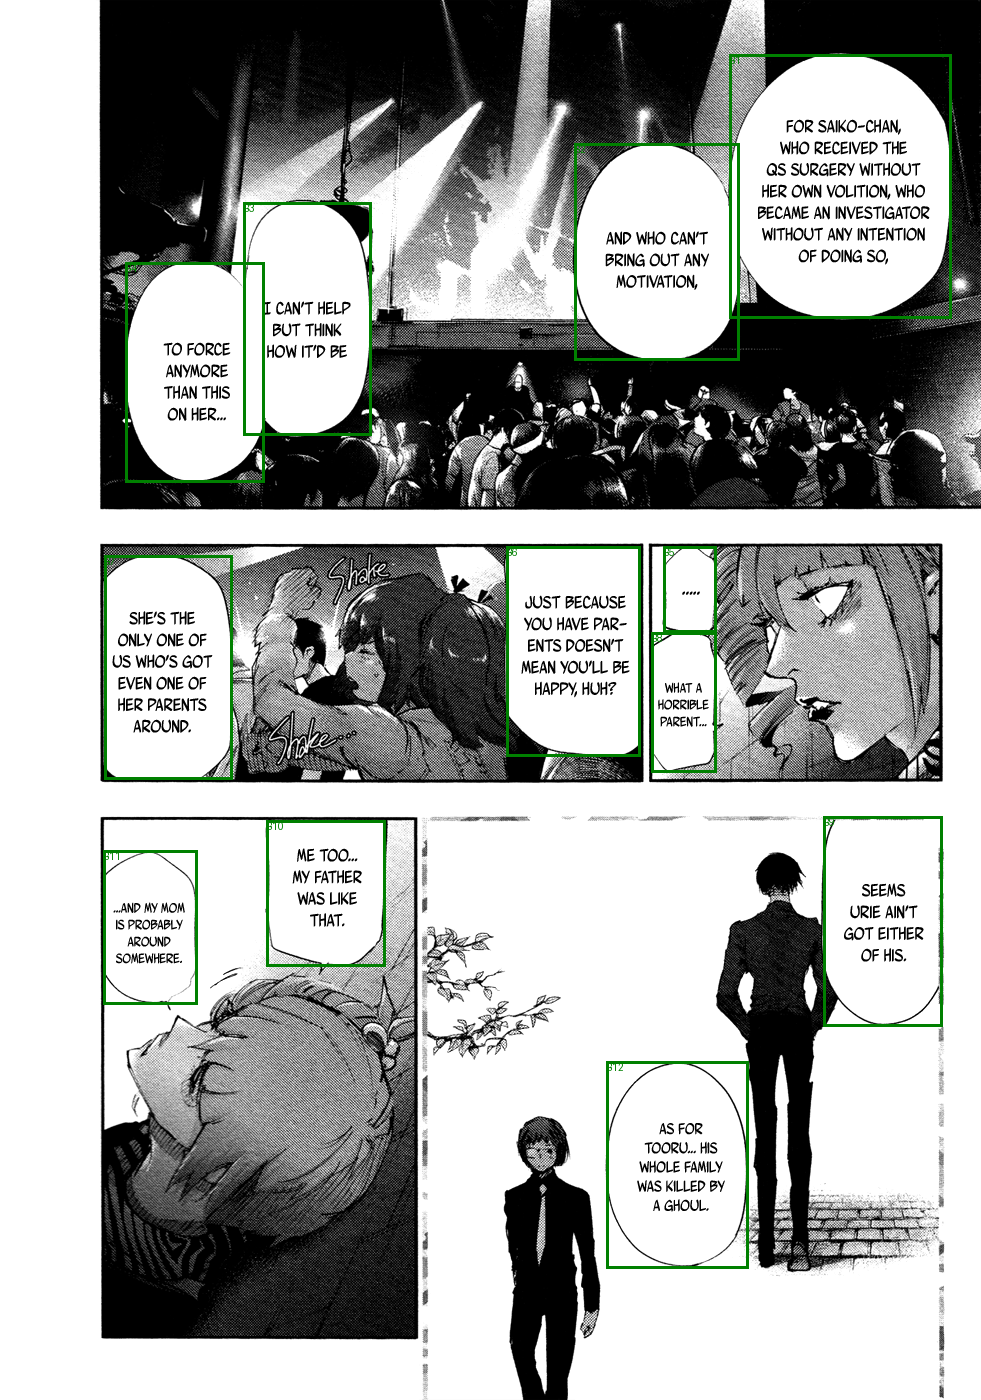

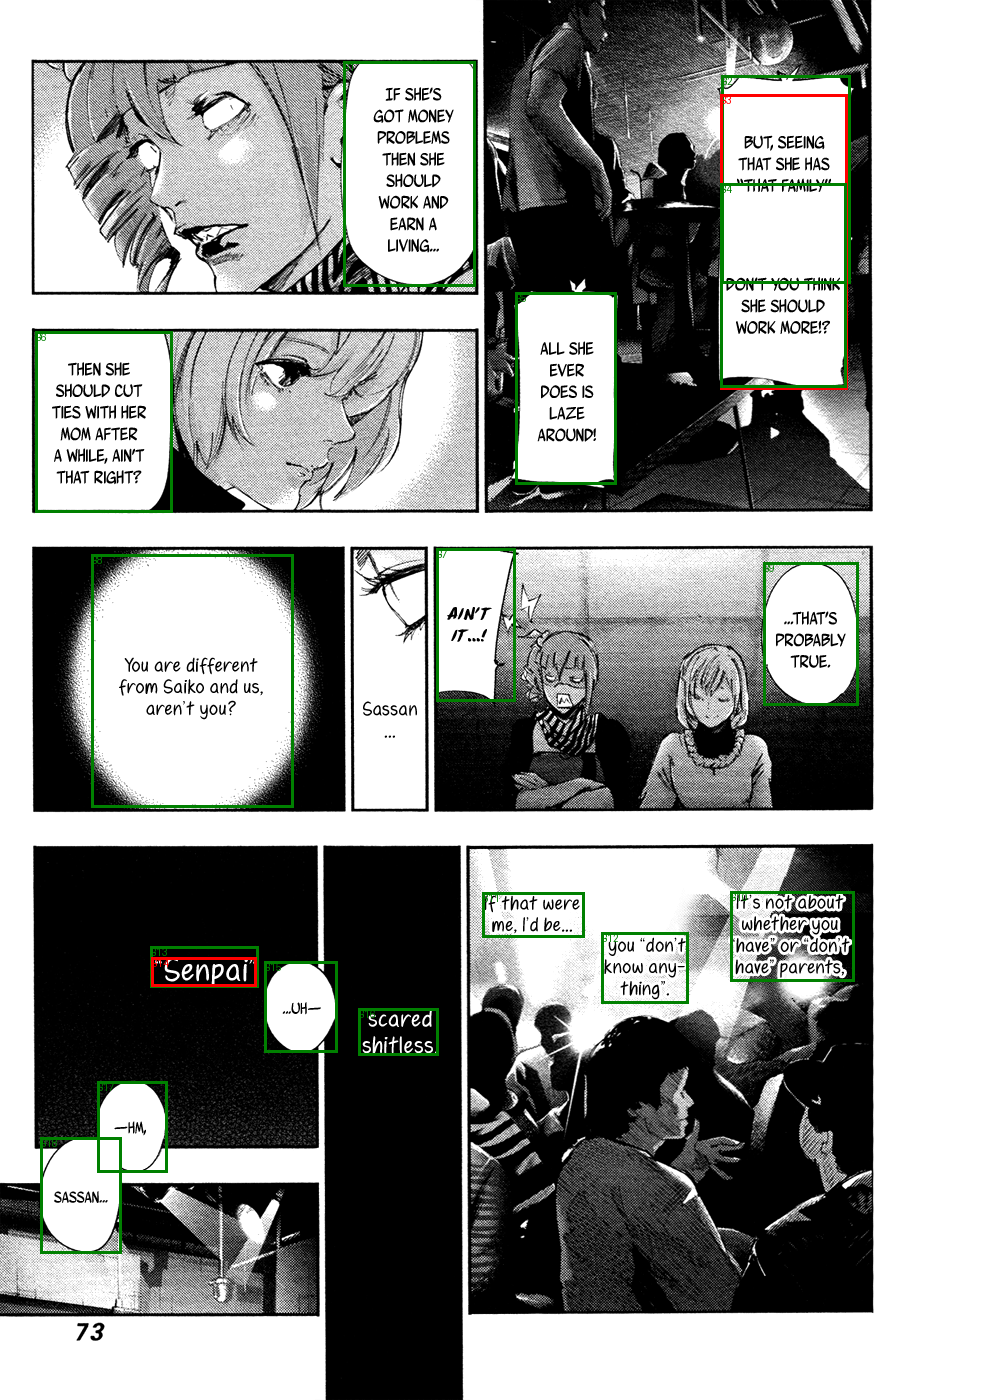

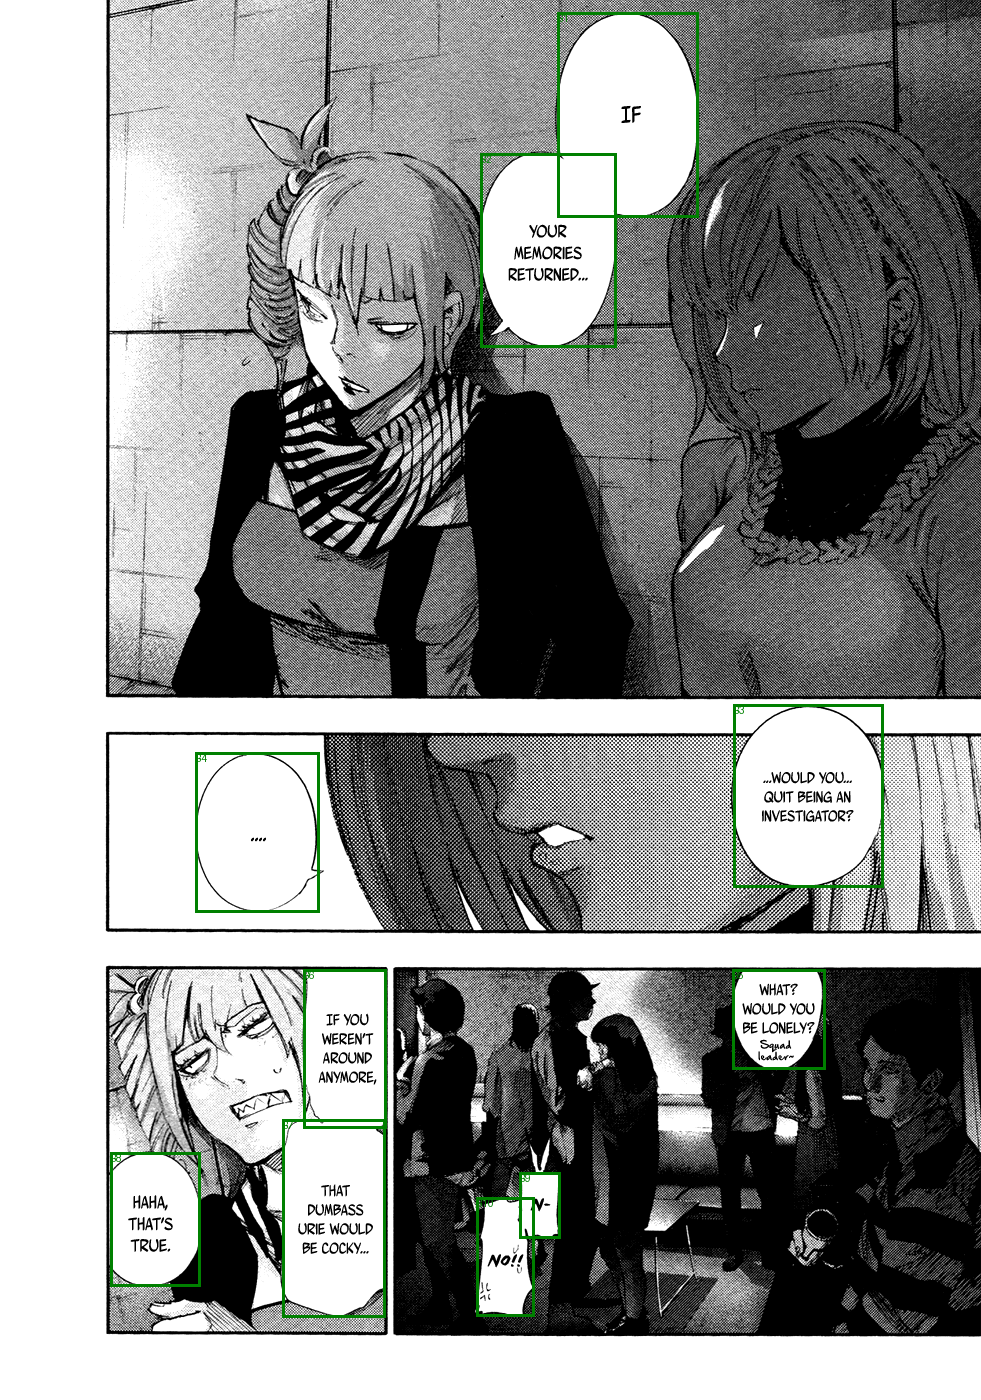

,sequence_id,page_index,page_file,candidates,kept,rejected,covered_texts,fallback_texts,cache,preview,signature
0,seq_e9ffbb64217c2fed,0,C:\Users\ESHAAN\BYTE\Applied-Task\Magi\TaskDat...,12,12,0,12,1,C:\Users\ESHAAN\BYTE\Applied-Task\Magi\FINETUN...,C:\Users\ESHAAN\BYTE\Applied-Task\Magi\FINETUN...,5c4d11d3cb24e7da37edeb4e4d11ffbfa9d416f155da9a...
1,seq_e9ffbb64217c2fed,1,C:\Users\ESHAAN\BYTE\Applied-Task\Magi\TaskDat...,18,16,2,16,1,C:\Users\ESHAAN\BYTE\Applied-Task\Magi\FINETUN...,C:\Users\ESHAAN\BYTE\Applied-Task\Magi\FINETUN...,ad2f32a79d5b2f1d61b58aafe84df5c801c1bd134d75e0...
2,seq_e9ffbb64217c2fed,2,C:\Users\ESHAAN\BYTE\Applied-Task\Magi\TaskDat...,10,10,0,10,0,C:\Users\ESHAAN\BYTE\Applied-Task\Magi\FINETUN...,C:\Users\ESHAAN\BYTE\Applied-Task\Magi\FINETUN...,c8497707254f2854f200437877841c5c79453e15d1e2c0...


In [56]:
from bubble_features import replace_visuals
original_visual_features = visual_features

def make_bubble_visual_features():
    sequence = dict(sequence_id=SEQUENCE_ID,
        pages=[dict(path=str(path), sha256=page['sha256'], width=page['width'], height=page['height'])
               for path,page in zip(PAGE_FILES, PAGE_METADATA)], boxes=boxes)
    baseline = {SEQUENCE_ID: {key: torch.tensor(value, dtype=torch.float)
                              for key,value in zip(BOX_KEYS, original_visual_features['visual'])}}
    vectors, summary = replace_visuals([sequence], BUBBLE_SETTINGS, baseline,
                                      EXPERIMENT_ROOT / 'cache_selected_ocr/bubbles/full_pipeline')
    audit = {}
    for item in summary:
        payload = torch.load(item['cache'], map_location='cpu', weights_only=True)
        for box in boxes:
            if box['page_index'] != item['page_index']:
                continue
            bubble_id = payload['text_to_bubble'].get(box['box_id'])
            bubble = next((b for b in payload['bubbles'] if b['bubble_id'] == bubble_id), None)
            audit[box['box_id']] = dict(bubble_id=bubble_id, bubble_bbox=bubble['box'] if bubble else None,
                visual_source='bubble_detr_encoder_mean' if bubble else 'original_magi_text_query')
    return dict(audit=[audit[k] for k in BOX_KEYS], keys=BOX_KEYS, visual=[vectors[SEQUENCE_ID][key] for key in BOX_KEYS],
                tail=original_visual_features['tail'], bubble_summary=summary)

visual_features = cached_stage('narration_bubbles',
    dict(original=stage_ref('narration_visual'), selector=stage_ref('ocr_selection'),
         settings=BUBBLE_SETTINGS, detector_sha256=NARRATION_INFO['bubble_detector_sha256'],
         helper_sha256=NARRATION_INFO['bubble_helper_sha256'],
         algorithm=function_digest(make_bubble_visual_features)), make_bubble_visual_features)
assert visual_features['keys'] == BOX_KEYS
for page in visual_features['bubble_summary']:
    display(Image.open(page['preview']))
display(pd.DataFrame(visual_features['bubble_summary']))


## 19. DeBERTa target-pooling function

Use the previous two OCR boxes on the same page, reserve the target tokens, and average target states only. Token budget and batch size come from the existing training configuration.

In [57]:
@torch.inference_mode()
def make_semantic_features():
    if not boxes:
        return dict(keys=[], text=[])
    tokenizer = AutoTokenizer.from_pretrained(str(DEBERTA_PATH), local_files_only=True)
    tokenizer.padding_side = 'right'
    model = AutoModel.from_pretrained(str(DEBERTA_PATH), local_files_only=True).cuda().eval()
    model.requires_grad_(False)
    assert model.config.hidden_size == 768
    items, history = [], {0: [], 1: [], 2: []}
    for box in boxes:
        context_ids = []
        for text in history[box['page_index']][-2:]:
            context_ids += tokenizer.encode(text, add_special_tokens=False) + [tokenizer.sep_token_id]
        target_ids = tokenizer.encode(box['ocr'], add_special_tokens=False) or [tokenizer.unk_token_id]
        budget = CONFIG['max_tokens'] - 2
        target_ids = target_ids[-budget:]
        remaining = budget - len(target_ids)
        context_ids = context_ids[-remaining:] if remaining else []
        ids = [tokenizer.cls_token_id] + context_ids + target_ids + [tokenizer.sep_token_id]
        target_mask = [0] * (1 + len(context_ids)) + [1] * len(target_ids) + [0]
        items.append((ids, target_mask))
        history[box['page_index']].append(box['ocr'])
    vectors = []
    try:
        size = CONFIG['semantic_batch_size']
        for start in range(0, len(items), size):
            batch = items[start:start+size]
            length = max(len(ids) for ids, mask in batch)
            ids = torch.full((len(batch), length), tokenizer.pad_token_id, dtype=torch.long, device='cuda')
            attention = torch.zeros_like(ids)
            target = torch.zeros_like(ids, dtype=torch.float)
            for i, (tokens, mask) in enumerate(batch):
                ids[i, :len(tokens)] = torch.tensor(tokens, device='cuda')
                attention[i, :len(tokens)] = 1
                target[i, :len(tokens)] = torch.tensor(mask, device='cuda')
            hidden = model(input_ids=ids, attention_mask=attention).last_hidden_state
            pooled = (hidden * target.unsqueeze(-1)).sum(1) / target.sum(1, keepdim=True)
            vectors.extend(pooled.float().cpu().tolist())
    finally:
        del model
        gc.collect()
        torch.cuda.empty_cache()
    return dict(keys=BOX_KEYS, text=vectors)


## 20. Reuse or create semantic features

The cache depends on selected OCR, context/pooling settings and local DeBERTa files. Changing the narration threshold will reuse these features.

In [58]:
semantic_features = cached_stage('narration_semantic',
    dict(selector=stage_ref('ocr_selection'), boxes=boxes, model=str(DEBERTA_PATH),
         model_files=training_config.model_files(DEBERTA_PATH), max_tokens=CONFIG['max_tokens'],
         context=2, pool='target_mean_v1', algorithm=function_digest(make_semantic_features)),
    make_semantic_features)
assert semantic_features['keys'] == BOX_KEYS


RUN   narration_semantic


The tokenizer you are loading from 'C:\Users\ESHAAN\BYTE\Applied-Task\Magi\FINETUNING-EXPERMENTS\NarrationModelwBubbles\runs_classifier_resume_v1_tuned_Bert\deberta' with an incorrect regex pattern: https://huggingface.co/mistralai/Mistral-Small-3.1-24B-Instruct-2503/discussions/84#69121093e8b480e709447d5e. This will lead to incorrect tokenization. You should set the `fix_mistral_regex=True` flag when loading this tokenizer to fix this issue.
c:\Users\ESHAAN\BYTE\godfather.venv\Lib\site-packages\torch\jit\_script.py:1491: FutureWarning: `torch.jit.script` is deprecated. Please switch to `torch.compile` or `torch.export`.
  warnings.warn(


## 21. Narration inference and threshold

One full sequence is one batch item. Attention is true for every real box, with no labels or padding needed. Save both logits and probabilities so thresholds can be reviewed later.
The classifier output is retained as `model_text_role`. The explicit tail rule changes only the final `text_role`; probabilities remain the model probabilities.


In [59]:
@torch.inference_mode()
def predict_narration():
    if not boxes:
        return []
    n = len(boxes)
    batch = dict(text=torch.tensor(semantic_features['text'], dtype=torch.float)[None],
                 visual=torch.tensor(visual_features['visual'], dtype=torch.float)[None],
                 tail=torch.tensor(visual_features['tail'], dtype=torch.float)[None],
                 geometry=torch.tensor(geometry, dtype=torch.float)[None],
                 page=torch.tensor([[b['page_index'] for b in boxes]], dtype=torch.long),
                 attention_mask=torch.ones((1, n), dtype=torch.bool))
    assert batch['text'].shape == (1, n, 768)
    assert batch['visual'].shape == (1, n, ckpt['visual_dim'])
    for tensor in batch.values():
        assert torch.isfinite(tensor).all()
    # CPU inference is sufficient for this small classifier and avoids holding another GPU model.
    output = narration_model(batch)
    if not isinstance(output, torch.Tensor) or output.shape != (1, n, 2):
        raise ValueError('Narration model must return [1, box_count, 2] SPOKEN/NARRATED logits.')
    if not torch.isfinite(output).all():
        raise ValueError('Narration model returned nonfinite logits.')
    logits = output[0]
    probabilities = logits.softmax(-1)
    return [dict(box_id=box['box_id'], page_index=box['page_index'], text_index=box['text_index'],
                 logits=logit.tolist(), p_spoken=float(probability[0]), p_narrated=float(probability[1]),
                 text_role='NARRATED' if float(probability[1]) >= NARRATION_THRESHOLD else 'SPOKEN')
            for box, logit, probability in zip(boxes, logits, probabilities)]

narration_predictions = cached_stage('narration_predictions',
    dict(semantic=stage_ref('narration_semantic'), visual=stage_ref('narration_bubbles'),
         geometry=geometry, model=NARRATION_INFO, threshold=NARRATION_THRESHOLD,
         algorithm=function_digest(predict_narration)), predict_narration)
assert [r['box_id'] for r in narration_predictions] == BOX_KEYS
display(pd.DataFrame(narration_predictions))


def apply_tail_rule(predictions, pages, enabled):
    """Force associated speech tails to SPOKEN; preserve the classifier output for audit."""
    output = []
    for prediction in predictions:
        record = dict(prediction)
        page = pages[record['page_index']]
        text_index = record['text_index']
        tail_ids = []
        for linked_text, tail_index in page.get('text_tail_associations', []):
            assert 0 <= linked_text < len(page['texts'])
            assert 0 <= tail_index < len(page.get('tails', [])), 'Invalid Magi tail association.'
            if linked_text == text_index:
                tail_ids.append(int(tail_index))
        force = bool(enabled and tail_ids)
        record['model_text_role'] = prediction['text_role']
        record['has_tail_association'] = bool(tail_ids)
        record['associated_tail_indices'] = sorted(set(tail_ids))
        record['tail_override'] = force and prediction['text_role'] != 'SPOKEN'
        record['decision_source'] = 'tail_rule' if force else 'classifier'
        if force:
            record['text_role'] = 'SPOKEN'
        output.append(record)
    return output


# Cache the postprocessing separately so switching the rule does not rerun encoders.
raw_narration_predictions = narration_predictions
narration_predictions = cached_stage('narration_tail_rule',
    dict(predictions=stage_ref('narration_predictions'), magi=stage_ref('magi_raw'),
         enabled=TAIL_FORCE_SPOKEN, qualification='explicit_text_tail_association',
         algorithm=function_digest(apply_tail_rule)),
    lambda: apply_tail_rule(raw_narration_predictions, magi_raw_results, TAIL_FORCE_SPOKEN))
print('Tail overrides:', sum(r['tail_override'] for r in narration_predictions))
display(pd.DataFrame(narration_predictions))


RUN   narration_predictions


,box_id,page_index,text_index,logits,p_spoken,p_narrated,text_role
0,PG1:T1,0,0,"[2.9261393547058105, -3.373070240020752]",0.998166,0.001834,SPOKEN
1,PG1:T2,0,1,"[2.950425148010254, -3.365507125854492]",0.998196,0.001804,SPOKEN
2,PG1:T3,0,2,"[2.9177608489990234, -3.359495162963867]",0.998125,0.001875,SPOKEN
3,PG1:T4,0,3,"[2.920980930328369, -3.3531932830810547]",0.998119,0.001881,SPOKEN
4,PG1:T5,0,4,"[2.9135236740112305, -3.361076593399048]",0.998120,0.001880,SPOKEN
5,PG1:T6,0,5,"[2.9251534938812256, -3.360097885131836]",0.998140,0.001860,SPOKEN
6,PG1:T7,0,6,"[2.924190044403076, -3.353105068206787]",0.998125,0.001875,SPOKEN
7,PG1:T8,0,7,"[2.9119696617126465, -3.3627729415893555]",0.998120,0.001880,SPOKEN
8,PG1:T9,0,8,"[2.923581123352051, -3.359215497970581]",0.998135,0.001865,SPOKEN
9,PG1:T10,0,9,"[2.926537275314331, -3.35201358795166]",0.998127,0.001873,SPOKEN


RUN   narration_tail_rule
Tail overrides: 0


,box_id,page_index,text_index,logits,p_spoken,p_narrated,text_role,model_text_role,has_tail_association,associated_tail_indices,tail_override,decision_source
0,PG1:T1,0,0,"[2.9261393547058105, -3.373070240020752]",0.998166,0.001834,SPOKEN,SPOKEN,False,[],False,classifier
1,PG1:T2,0,1,"[2.950425148010254, -3.365507125854492]",0.998196,0.001804,SPOKEN,SPOKEN,False,[],False,classifier
2,PG1:T3,0,2,"[2.9177608489990234, -3.359495162963867]",0.998125,0.001875,SPOKEN,SPOKEN,False,[],False,classifier
3,PG1:T4,0,3,"[2.920980930328369, -3.3531932830810547]",0.998119,0.001881,SPOKEN,SPOKEN,True,[3],False,tail_rule
4,PG1:T5,0,4,"[2.9135236740112305, -3.361076593399048]",0.998120,0.001880,SPOKEN,SPOKEN,False,[],False,classifier
5,PG1:T6,0,5,"[2.9251534938812256, -3.360097885131836]",0.998140,0.001860,SPOKEN,SPOKEN,True,[1],False,tail_rule
6,PG1:T7,0,6,"[2.924190044403076, -3.353105068206787]",0.998125,0.001875,SPOKEN,SPOKEN,False,[],False,classifier
7,PG1:T8,0,7,"[2.9119696617126465, -3.3627729415893555]",0.998120,0.001880,SPOKEN,SPOKEN,False,[],False,classifier
8,PG1:T9,0,8,"[2.923581123352051, -3.359215497970581]",0.998135,0.001865,SPOKEN,SPOKEN,False,[],False,classifier
9,PG1:T10,0,9,"[2.926537275314331, -3.35201358795166]",0.998127,0.001873,SPOKEN,SPOKEN,False,[],False,classifier


## 22. Final speaker routing

Narrated boxes get speaker NARRATION. Spoken boxes use the inferred entity ID; missing/ambiguous entities remain null. Raw association candidates are kept for inspection.

In [60]:
def make_full_records():
    assert len(text_entities) == len(narration_predictions)
    output = []
    for raw, role in zip(text_entities, narration_predictions):
        assert (raw['page_index'], raw['text_index']) == (role['page_index'], role['text_index'])
        record = dict(raw)
        record.update(role)
        record.update(ocr_agreement[raw['page_index']][raw['text_index']])
        box_index = BOX_KEYS.index(role['box_id'])
        record.update(visual_features['audit'][box_index])
        record['tail_score'] = float(visual_features['tail'][box_index][0])
        narrated = role['text_role'] == 'NARRATED'
        record['speaker'] = 'NARRATION' if narrated else raw['entity_id']
        record['speaker_status'] = 'narrator' if narrated else raw['association_status']
        record['needs_review'] = (ocr_selection[raw['page_index']][raw['text_index']]['needs_review']
                                  or (not narrated and raw['association_status'] != 'linked'))
        output.append(record)
    return output

full_records = cached_stage('full_records',
    dict(ocr_filter=stage_ref('ocr_agreement'),speakers=stage_ref('text_entities'), narration=stage_ref('narration_tail_rule'), bubbles=stage_ref('narration_bubbles'),
         algorithm=function_digest(make_full_records)), make_full_records)
# Preserve the original candidate records; the viewer uses the new final records.
text_entities = full_records
display(pd.DataFrame([r for r in full_records if not r['delete_ocr']], columns=['box_id', 'text', 'text_role', 'p_narrated',
                                           'model_text_role', 'tail_override', 'visual_source', 'speaker', 'speaker_status', 'needs_review']))

# All rejected records remain available for crop inspection and audit exports.
deleted_ocr_records=[r for r in full_records if r['delete_ocr']]
display(pd.DataFrame(deleted_ocr_records,columns=['box_id','text','ocr_agreement','deletion_reason']))


RUN   full_records


,box_id,text,text_role,p_narrated,model_text_role,tail_override,visual_source,speaker,speaker_status,needs_review
0,PG1:T1,"FOR SAIKO-CHAN, WHO RECEIVED THE QS SURGERY WI...",SPOKEN,0.001834,SPOKEN,False,bubble_detr_encoder_mean,E7,linked,False
1,PG1:T2,"AND WHO CAN'T BRING OUT ANY MOTIVATION,",SPOKEN,0.001804,SPOKEN,False,bubble_detr_encoder_mean,E7,linked,False
2,PG1:T3,I CAN'T HELP BUT THINK HOW IT'D BE,SPOKEN,0.001875,SPOKEN,False,bubble_detr_encoder_mean,E7,linked,False
3,PG1:T4,TO FORCE ANYMORE THAN THIS ON HER...,SPOKEN,0.001881,SPOKEN,False,bubble_detr_encoder_mean,E7,linked,False
4,PG1:T5,44444,SPOKEN,0.001880,SPOKEN,False,bubble_detr_encoder_mean,E7,linked,False
5,PG1:T6,WHAT A HORRIBLE PARENT...,SPOKEN,0.001860,SPOKEN,False,bubble_detr_encoder_mean,E7,linked,False
6,PG1:T7,JUST BECAUSE YOU HAVE PAR- ENTS DOESN'T MEAN Y...,SPOKEN,0.001875,SPOKEN,False,bubble_detr_encoder_mean,E7,linked,False
7,PG1:T8,hake,SPOKEN,0.001880,SPOKEN,False,original_magi_text_query,E4,linked,False
8,PG1:T9,SHE'S THE ONLY ONE OF US WHO'S GOT EVEN ONE OF...,SPOKEN,0.001865,SPOKEN,False,bubble_detr_encoder_mean,E7,linked,False
9,PG1:T10,SEEMS URIE AIN'T GOT EITHER OF HIS.,SPOKEN,0.001873,SPOKEN,False,bubble_detr_encoder_mean,E6,linked,False


,box_id,text,ocr_agreement,deletion_reason
0,PG3:T1,IF,0.181818,OCR agreement below 0.4


## 23. Annotated page viewer functions

Orange boxes are narration; blue boxes are spoken. Labels show narration probability, selected OCR and final speaker. Toggle panels, characters, tails, IDs and associations. inspect_text displays the crop and full record.

In [61]:
def center(box):
    x1, y1, x2, y2 = box
    return ((x1+x2)/2, (y1+y2)/2)


def draw_box(ax, box, color, label=None):
    x1, y1, x2, y2 = box
    ax.add_patch(patches.Rectangle((x1, y1), x2-x1, y2-y1, linewidth=2,
                                   edgecolor=color, facecolor='none'))
    if label:
        ax.text(x1, max(0, y1-4), label, fontsize=8, color='white',
                bbox=dict(facecolor='black', alpha=0.7, edgecolor='none'))


def show_page(page_index=0, panels=False, texts=True, characters=True, tails=False,
              same_character=False, text_character=True, text_tail=False,
              ocr=True, ids=True, entities=True, ocr_source='selected', save_path=None, show_deleted=False):
    result = per_page_results[page_index]
    assert ocr_source in {'selected', 'paddle', 'magi'}
    cmap = plt.get_cmap('tab20', max(len(identified_char), 1))
    colors = {entity_id: cmap(i) for i, entity_id in enumerate(identified_char)}
    page_records = [r for r in text_entities if r['page_index'] == page_index]
    fig, ax = plt.subplots(figsize=(12, 18))
    ax.imshow(chapter_pages[page_index])
    if panels:
        for i, box in enumerate(result.get('panels', [])):
            draw_box(ax, box, 'green', f'PN{i+1}' if ids else None)
    if texts:
        for i, box in enumerate(result['texts']):
            record = page_records[i]
            if record['delete_ocr'] and not show_deleted:
                continue
            essential = result.get('is_essential_text', [])
            color = 'darkorange' if record['text_role'] == 'NARRATED' else 'deepskyblue'
            if record['delete_ocr']: color='red'
            label = f'T{i+1}' if ids else ''
            if record['delete_ocr']: label += ' [deleted: '+record['deletion_reason']+']'
            label += f" | {record['text_role']} p={record['p_narrated']:.2f}"
            if record.get('tail_override'):
                label += ' [tail override]'
            if entities:
                label += ' | speaker=' + (record['speaker'] or record['speaker_status'])
            if ocr:
                text = (result['ocr'][i] if ocr_source == 'selected' else
                        ocr_selection[page_index][i][f'{ocr_source}_text']) or ''
                label += ' | ' + (text[:62] + '…' if len(text) > 65 else text)
            if record['needs_review']:
                label += ' [review]'
            draw_box(ax, box, color, label.strip(' |'))
    if characters:
        for i, box in enumerate(result['characters']):
            char_id = f'PG{page_index+1}:C{i+1}'
            entity_id = char_to_entity[char_id]
            label = f'C{i+1} / CL{int(result["character_cluster_labels"][i])+1}' if ids else ''
            if entities:
                label += f' | {entity_id}'
            draw_box(ax, box, colors[entity_id] if entities else 'blue', label.strip(' |'))
    if tails:
        for i, box in enumerate(result.get('tails', [])):
            draw_box(ax, box, 'purple', f'TAIL{i+1}' if ids else None)
    if same_character:
        for indices in page_clusters(result, page_index).values():
            for index in indices[1:]:
                a, b = center(result['characters'][indices[0]]), center(result['characters'][index])
                ax.plot([a[0], b[0]], [a[1], b[1]], color='blue', linewidth=1.5)
    for enabled, key, target, style in [
        (text_character, 'text_character_associations', 'characters', '--'),
        (text_tail, 'text_tail_associations', 'tails', ':')]:
        if enabled:
            for text_index, target_index in result.get(key, []):
                if page_records[text_index]['delete_ocr'] and not show_deleted:
                    continue
                # Retain raw links in detailed output, but hide speaker links for narration in the viewer.
                if target == 'characters' and page_records[text_index]['text_role'] == 'NARRATED':
                    continue
                if not (0 <= text_index < len(result['texts']) and 0 <= target_index < len(result.get(target, []))):
                    continue
                a, b = center(result['texts'][text_index]), center(result[target][target_index])
                color = 'purple' if target == 'tails' else 'blue'
                if entities and target == 'characters':
                    color = colors[char_to_entity[f'PG{page_index+1}:C{target_index+1}']]
                ax.plot([a[0], b[0]], [a[1], b[1]], color=color, linestyle=style, linewidth=1.5)
                if ids:
                    target_id = f'C{target_index+1}' if target == 'characters' else f'TAIL{target_index+1}'
                    ax.text((a[0]+b[0])/2, (a[1]+b[1])/2, f'T{text_index+1}→{target_id}', fontsize=7)
    ax.set_title(f'{SEQUENCE_ID} | PG{page_index+1}: {PAGE_FILES[page_index].name} | {ocr_source} OCR')
    ax.axis('off')
    fig.tight_layout()
    if save_path is not None:
        save_path = Path(save_path)
        save_path.parent.mkdir(parents=True, exist_ok=True)
        fig.savefig(save_path, bbox_inches='tight', dpi=150)
    plt.show()
    plt.close(fig)


def inspect_text(page_index=0, text_index=0):
    decision = ocr_selection[page_index][text_index]
    crop, _ = crop_box(chapter_pages[page_index], decision['box'])
    if crop is not None:
        display(Image.fromarray(crop))
    record = next(r for r in text_entities if r['page_index'] == page_index and r['text_index'] == text_index)
    print(json.dumps(dict(ocr_decision=decision, text_entity=record), ensure_ascii=False, indent=2))


## 24. Interactive annotated pages

Select a page and OCR source. Toggle annotation layers without rerunning models. If widgets are unavailable, use the direct-call cell below.

In [62]:
page_control = widgets.Dropdown(options=[(f'PG{i+1} — {p.name}', i) for i, p in enumerate(PAGE_FILES)], description='Page:')
source_control = widgets.Dropdown(options=['selected', 'paddle', 'magi'], description='OCR:')
flags = {name: widgets.Checkbox(value=value, description=name.replace('_', ' '), indent=False)
         for name, value in dict(panels=False, texts=True, characters=True, tails=False,
                                 same_character=False, text_character=True, text_tail=False,
                                 ocr=True, ids=True, entities=True, show_deleted=False).items()}
controls = dict(page_index=page_control, ocr_source=source_control, **flags)
viewer_output = widgets.interactive_output(show_page, controls)
display(widgets.VBox([widgets.HBox([page_control, source_control]),
                      widgets.HBox(list(flags.values())[:5]), widgets.HBox(list(flags.values())[5:])]), viewer_output)


Output()

## 25. Direct viewer calls and optional image export

Display page 1 directly. Uncomment examples to inspect a crop or save annotated PNGs for every page.

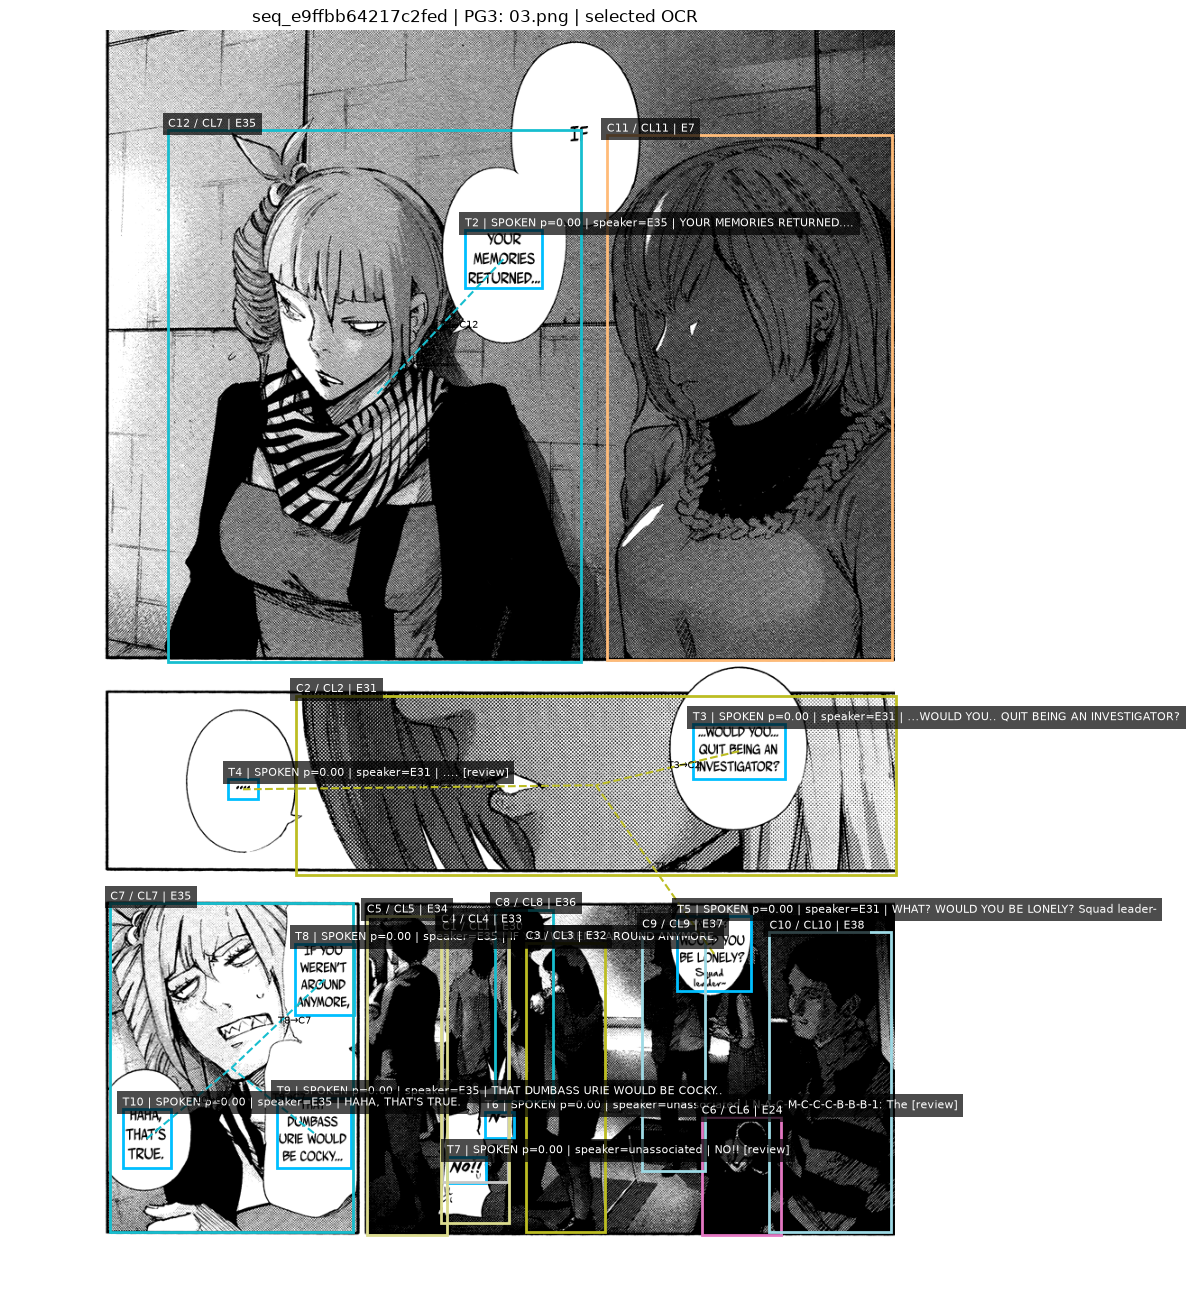

In [63]:
show_page(2)
# inspect_text(page_index=0, text_index=0)
# show_page(0, panels=True, tails=True, text_tail=True)
# for page_index in range(len(PAGE_FILES)):
#     show_page(page_index, save_path=OUTPUT_DIR / 'annotations' / f'{page_index+1:02d}.png')


## 26. Export dialogue and detailed predictions

Save ordered page dialogue plus every box’s logits, probabilities, OCR provenance and association candidates. Optional essential filtering only changes dialogue_pages.json, never model context or detailed records.

In [64]:
expected = [(p, t) for p, page in enumerate(magi_raw_results) for t in range(len(page['texts']))]
assert [(r['page_index'], r['text_index']) for r in full_records] == expected
dialogue_pages = [[] for _ in PAGE_FILES]
for record in full_records:
    if record['delete_ocr']:
        continue
    page_index, text_index = record['page_index'], record['text_index']
    if EXPORT_ESSENTIAL_ONLY:
        flags = magi_raw_results[page_index].get('is_essential_text')
        assert flags is not None and len(flags) == len(magi_raw_results[page_index]['texts'])
        if not flags[text_index]:
            continue
    dialogue_pages[page_index].append(dict(speaker=record['speaker'], text=record['text']))
write_json(OUTPUT_DIR / 'dialogue_pages.json', dialogue_pages)
write_json(OUTPUT_DIR / 'box_predictions.json', full_records)
pd.DataFrame(full_records).to_csv(OUTPUT_DIR / 'box_predictions.csv', index=False)
write_json(OUTPUT_DIR / 'deleted_ocr.json', deleted_ocr_records)
pd.DataFrame(deleted_ocr_records).to_csv(OUTPUT_DIR / 'deleted_ocr.csv',index=False)
write_json(OUTPUT_DIR / 'entities.json', entity_results)
write_json(OUTPUT_DIR / 'run_metadata.json', dict(sequence_id=SEQUENCE_ID, pages=PAGE_METADATA,
    narration_model=NARRATION_INFO, narration_model_args=model_args,
    narration_threshold=NARRATION_THRESHOLD,
    tail_rule=dict(enabled=TAIL_FORCE_SPOKEN, qualification='explicit_text_tail_association'), character_checkpoint=CHECKPOINT_INFO,
    bubble_stage=stage_ref('narration_bubbles'), trained_on_bubble_features=TRAINED_ON_BUBBLES,
    entity_threshold=ENTITY_THRESHOLD, essential_filter=EXPORT_ESSENTIAL_ONLY,
    ocr_filter=dict(agreement_delete_below=OCR_AGREEMENT_DELETE_BELOW,delete_sfx=True,missing_agreement='keep unless SFX',stage=stage_ref('ocr_agreement')),
    association_head=str(ASSOCIATION_HEAD_PATH) if ASSOCIATION_HEAD_PATH else 'original_magi',
    cache_manifest=str(MANIFEST_PATH), stages=manifest['stages']))
display(pd.DataFrame([dict(page=p+1, detected=len(magi_raw_results[p]['texts']),
    narrated=sum(r['text_role'] == 'NARRATED' for r in full_records if r['page_index'] == p),
    deleted_ocr=sum(r['delete_ocr'] for r in full_records if r['page_index']==p),
    exported=len(dialogue_pages[p])) for p in range(len(PAGE_FILES))]))
print('Saved outputs:', OUTPUT_DIR)
print('No training or ground-truth labels were used.')


# A simple readable transcript; retain per-box order, including multiple texts in one bubble.
lines = []
for page_index, page_file in enumerate(PAGE_FILES):
    lines.append(f'[Page {page_file.name}]')
    for record in full_records:
        if record['delete_ocr'] or record['page_index'] != page_index:
            continue
        if EXPORT_ESSENTIAL_ONLY and not magi_raw_results[page_index]['is_essential_text'][record['text_index']]:
            continue
        speaker = record['speaker'] or 'UNKNOWN'
        lines.append(f"{speaker}: {record['text']}")
    lines.append('')
transcript = '\n'.join(lines)
(OUTPUT_DIR / 'transcript.txt').write_text(transcript, encoding='utf-8')
print(transcript)


,page,detected,narrated,deleted_ocr,exported
0,1,13,0,0,13
1,2,17,0,0,17
2,3,10,0,1,9


Saved outputs: C:\Users\ESHAAN\BYTE\Applied-Task\Magi\FINETUNING-EXPERMENTS\NarrationModelwBubbles\cache_selected_ocr\full_pipeline\test\seq_e9ffbb64217c2fed\sequence\pipelineContour_outputs
No training or ground-truth labels were used.
[Page 01.png]
E7: FOR SAIKO-CHAN, WHO RECEIVED THE QS SURGERY WITHOUT HER OWN VOLITION, WHO BECAME AN INVESTIGATOR WITHOUT ANY INTENTION OF DOING SO,
E7: AND WHO CAN'T BRING OUT ANY MOTIVATION,
E7: I CAN'T HELP BUT THINK HOW IT'D BE
E7: TO FORCE ANYMORE THAN THIS ON HER...
E7: 44444
E7: WHAT A HORRIBLE PARENT...
E7: JUST BECAUSE YOU HAVE PAR- ENTS DOESN'T MEAN YOU'LL BE HAPPY, HUH?
E4: hake
E7: SHE'S THE ONLY ONE OF US WHO'S GOT EVEN ONE OF HER PARENTS AROUND.
E6: SEEMS URIE AIN'T GOT EITHER OF HIS.
E6: AS FOR TOORU... HIS WHOLE FAMILY WAS KILLED BY A GHOUL.
E8: ME TOO... MY FATHER WAS LIKE THAT.
E8: .….AND MY MOM IS PROBABLY AROUND SOMEWHERE.

[Page 02.png]
E28: BUT, SEEING THAT SHE HAS "THAT FAMILY"
E28: DON'T YOU THINK SHE SHOULD WORK MORE!?
E23: ALL

## Contour grouping settings
Reuse the tested checks in `contour_grouping.py`, copied from checkingContour.ipynb. All earlier model/OCR stages stay the same. Only the new grouping stage depends on these settings. A failed individual check receives the faint retry; first-pass successes are preserved.


In [65]:
import math
CONTOUR_HELPER=MAGI_ROOT/'paddleOCR-Magi/contour_grouping.py'
contour_grouping=load_local_module('pipeline_contour_grouping',CONTOUR_HELPER)
CONTOUR_SETTINGS=dict(contour_grouping.CHECK)
FAINT_SETTINGS=dict(contour_grouping.FAINT)
# Optional edits here affect only this inspection/grouping stage.
# CONTOUR_SETTINGS['expand']=0.20
contour_grouping.FAINT=FAINT_SETTINGS
for name in ['contour_candidates','grouped_records']:
    FORCE[name]=False
    STAGE_VERSIONS[name]=1


## Check individual bubbles and select merge candidates
Load all YOLO detections from the existing bubble feature cache, including detections previously discarded from visual features. Match only surviving Magi texts. Ignore YOLO boxes without a surviving match. Run the same individual contour checks and failed-only faint retry; select overlapping pairs/components containing an unresolved member. Prefer a full component over its smaller pairs. Do not test a merged boundary. Cache the checks and selected groups independently of model predictions.


In [66]:
def make_contour_candidates():
    results=[]
    summaries={int(s['page_index']):s for s in visual_features['bubble_summary']}
    for page_index,path in enumerate(PAGE_FILES):
        summary=summaries[page_index]
        saved=torch.load(summary['cache'],map_location='cpu',weights_only=True)
        assert saved['signature']==summary['signature'],'Bubble cache identity changed'
        assert saved['page']['sha256']==file_hash(path),'Bubble cache page changed'
        bubbles=[dict(box=b['box'],confidence=b['confidence']) for b in saved['bubbles']]
        records=[r for r in full_records if r['page_index']==page_index]
        with Image.open(path) as source:
            result=contour_grouping.inspect_page_groups(bubbles,source.convert('RGB'),records,CONTOUR_SETTINGS)
        results.append(result)
    return results

contour_candidates=cached_stage('contour_candidates',
    dict(ocr_filter=stage_ref('ocr_agreement'),selector=stage_ref('ocr_selection'),
         bubbles=stage_ref('narration_bubbles'),settings=CONTOUR_SETTINGS,faint=FAINT_SETTINGS,
         helper_sha256=file_hash(CONTOUR_HELPER),algorithm=function_digest(make_contour_candidates)),
    make_contour_candidates)
for page_index,analysis in enumerate(contour_candidates):
    print('Page',PAGE_FILES[page_index].name,'| ignored YOLO boxes:',analysis['ignored_candidate_ids'])
    display(pd.DataFrame(analysis['individual'],columns=['candidate_id','text_ids','boundary_found','detection_pass','reasons']))
    display(pd.DataFrame(analysis['merge_candidates']))


RUN   contour_candidates
Page 01.png | ignored YOLO boxes: []


,candidate_id,text_ids,boundary_found,detection_pass,reasons
0,0,[PG1:T1],False,first,crop-truncated region; crop edge is not outlin...
1,1,[PG1:T2],False,first,crop-truncated region; crop edge is not outlin...
2,2,[PG1:T3],False,first,crop-truncated region; crop edge is not outlin...
3,3,[PG1:T4],False,first,crop-truncated region; crop edge is not outlin...
4,4,[PG1:T5],False,first,crop-truncated region; crop edge is not outlin...
5,5,[PG1:T7],True,first,passed provisional checks
6,6,[PG1:T9],True,first,passed provisional checks
7,7,[PG1:T6],False,first,crop-truncated region; crop edge is not outlin...
8,8,[PG1:T10],False,first,does not enclose text; interior not mostly whi...
9,9,[PG1:T12],True,first,passed provisional checks


,group_id,candidate_ids,text_ids,unresolved_candidate_ids
0,M1,"[0, 1]","[PG1:T1, PG1:T2]","[0, 1]"
1,M2,"[2, 3]","[PG1:T3, PG1:T4]","[2, 3]"


Page 02.png | ignored YOLO boxes: []


,candidate_id,text_ids,boundary_found,detection_pass,reasons
0,0,[PG2:T4],True,first,passed provisional checks
1,1,[PG2:T1],False,first,crop-truncated region; crop edge is not outlin...
2,2,"[PG2:T1, PG2:T2]",True,first,passed provisional checks
3,3,[PG2:T2],False,first,crop-truncated region; crop edge is not outlin...
4,4,[PG2:T3],True,first,ambiguous shape
5,5,[PG2:T5],True,first,passed provisional checks
6,6,[PG2:T7],True,first,ambiguous shape
7,7,[PG2:T9],True,first,ambiguous shape
8,8,[PG2:T6],True,first,passed provisional checks
9,9,[PG2:T10],False,first,does not enclose text; crop-truncated region; ...


,group_id,candidate_ids,text_ids,unresolved_candidate_ids
0,M1,"[1, 2, 3]","[PG2:T1, PG2:T2]","[1, 3]"
1,M2,"[12, 13]",[PG2:T15],"[12, 13]"
2,M3,"[16, 17]","[PG2:T16, PG2:T17]","[16, 17]"


Page 03.png | ignored YOLO boxes: [0]


,candidate_id,text_ids,boundary_found,detection_pass,reasons
0,1,[PG3:T2],False,first,crop-truncated region; crop edge is not outlin...
1,2,[PG3:T3],True,first,passed provisional checks
2,3,[PG3:T4],False,first,crop-truncated region; crop edge is not outlin...
3,4,[PG3:T5],False,first,does not enclose text; insufficient real drawn...
4,5,[PG3:T8],False,first,crop-truncated region; crop edge is not outlin...
5,6,[PG3:T9],False,first,crop-truncated region; crop edge is not outlin...
6,7,[PG3:T10],True,first,passed provisional checks
7,8,[PG3:T6],False,first,does not enclose text; crop-truncated region; ...
8,9,[PG3:T7],False,first,crop-truncated region; crop edge is not outlin...


,group_id,candidate_ids,text_ids,unresolved_candidate_ids
0,M1,"[5, 6]","[PG3:T8, PG3:T9]","[5, 6]"
1,M2,"[8, 9]","[PG3:T6, PG3:T7]","[8, 9]"


## Concatenate surviving OCR in Magi reading order
Only merge-candidate membership joins texts; individual or merged boundary success does not gate concatenation. Deleted texts never reappear. Each surviving text is emitted exactly once. Original narration and speaker predictions are retained for every member; mixed results are displayed for review, never silently overridden.


In [67]:
def make_grouped_records():
    # Respect the optional original export filter too; default EXPORT_ESSENTIAL_ONLY is False.
    records=full_records
    if EXPORT_ESSENTIAL_ONLY:
        records=[r for r in records if magi_raw_results[r['page_index']]['is_essential_text'][r['text_index']]]
    rows,assignments=contour_grouping.concatenate_records(records,contour_candidates)
    return dict(rows=rows,assignments=assignments)

grouped=cached_stage('grouped_records',
    dict(records=stage_ref('full_records'),candidates=stage_ref('contour_candidates'),
         essential_filter=EXPORT_ESSENTIAL_ONLY,helper_sha256=file_hash(CONTOUR_HELPER),
         algorithm=function_digest(make_grouped_records)),make_grouped_records)
grouped_records=grouped['rows']
display(pd.DataFrame(grouped_records,columns=['page_index','group_id','box_ids','text','speaker','text_role','grouping_source','needs_review']))
display(pd.DataFrame(grouped['assignments']))


RUN   grouped_records


,page_index,group_id,box_ids,text,speaker,text_role,grouping_source,needs_review
0,0,PG1:M1,"[PG1:T1, PG1:T2]","FOR SAIKO-CHAN, WHO RECEIVED THE QS SURGERY WI...",E7,SPOKEN,overlap_candidate,False
1,0,PG1:M2,"[PG1:T3, PG1:T4]",I CAN'T HELP BUT THINK HOW IT'D BE TO FORCE AN...,E7,SPOKEN,overlap_candidate,False
2,0,PG1:S_PG1:T5,[PG1:T5],44444,E7,SPOKEN,standalone,False
3,0,PG1:S_PG1:T6,[PG1:T6],WHAT A HORRIBLE PARENT...,E7,SPOKEN,standalone,False
4,0,PG1:S_PG1:T7,[PG1:T7],JUST BECAUSE YOU HAVE PAR- ENTS DOESN'T MEAN Y...,E7,SPOKEN,standalone,False
5,0,PG1:S_PG1:T8,[PG1:T8],hake,E4,SPOKEN,standalone,False
6,0,PG1:S_PG1:T9,[PG1:T9],SHE'S THE ONLY ONE OF US WHO'S GOT EVEN ONE OF...,E7,SPOKEN,standalone,False
7,0,PG1:S_PG1:T10,[PG1:T10],SEEMS URIE AIN'T GOT EITHER OF HIS.,E6,SPOKEN,standalone,False
8,0,PG1:S_PG1:T11,[PG1:T11],AS FOR TOORU... HIS WHOLE FAMILY WAS KILLED BY...,E6,SPOKEN,standalone,False
9,0,PG1:S_PG1:T12,[PG1:T12],ME TOO... MY FATHER WAS LIKE THAT.,E8,SPOKEN,standalone,False


,box_id,page_index,group_id,alternatives,assignment_ambiguous
0,PG1:T1,0,PG1:M1,[],False
1,PG1:T2,0,PG1:M1,[],False
2,PG1:T3,0,PG1:M2,[],False
3,PG1:T4,0,PG1:M2,[],False
4,PG1:T5,0,PG1:S_PG1:T5,[],False
5,PG1:T6,0,PG1:S_PG1:T6,[],False
6,PG1:T7,0,PG1:S_PG1:T7,[],False
7,PG1:T8,0,PG1:S_PG1:T8,[],False
8,PG1:T9,0,PG1:S_PG1:T9,[],False
9,PG1:T10,0,PG1:S_PG1:T10,[],False


## View page groups and their OCR crops
Select a page to see YOLO candidates, individual outlines, and grouped Magi text boxes. Green candidates have individual boundaries; orange candidates remain unresolved. Text boxes sharing a group use the same color. These outlines do not imply a successful merged boundary. Deleted OCR never appears in the grouped view. Inspect a group below to see its original text crops and member predictions.


In [68]:
def show_contour_groups(page_index=0,individual_outlines=True):
    analysis=contour_candidates[page_index]
    with Image.open(PAGE_FILES[page_index]) as source:page=source.convert('RGB')
    fig,ax=plt.subplots(figsize=(12,18));ax.imshow(page)
    for candidate in analysis['individual']:
        color='limegreen' if candidate['boundary_found'] else 'darkorange'
        draw_box(ax,candidate['box'],color,f"B{candidate['candidate_id']} | boundary={candidate['boundary_found']}")
        if individual_outlines and candidate['contour_points']:
            points=np.asarray(candidate['contour_points']);points=np.vstack([points,points[0]])
            ax.plot(points[:,0],points[:,1],color=color,linewidth=1)
    by_id={r['box_id']:r for r in full_records}
    rows=[r for r in grouped_records if r['page_index']==page_index]
    for i,row in enumerate(rows):
        color=plt.get_cmap('tab20')(i%20)
        for bid in row['box_ids']:
            draw_box(ax,by_id[bid]['box'],color,f"{row['group_id']} | {bid}")
    ax.axis('off');fig.tight_layout();plt.show()
    display(pd.DataFrame(rows,columns=['group_id','box_ids','text','speaker','text_role']))


def inspect_group(group_id):
    row=next(r for r in grouped_records if r['group_id']==group_id)
    print(row['text']);display(pd.DataFrame(row['member_predictions']))
    by_id={r['box_id']:r for r in full_records}
    with Image.open(PAGE_FILES[row['page_index']]) as source:
        for bid in row['box_ids']:
            record=by_id[bid];a,b,c,d=record['box']
            print(bid,record['text'])
            display(source.crop((max(0,int(a)),max(0,int(b)),min(source.width,math.ceil(c)),min(source.height,math.ceil(d)))))

page_picker=widgets.Dropdown(options=[(p.name,i) for i,p in enumerate(PAGE_FILES)],description='Page:')
display(widgets.interactive(show_contour_groups,page_index=page_picker,individual_outlines=True))
if grouped_records:
    group_picker=widgets.Dropdown(options=[r['group_id'] for r in grouped_records],description='Group:')
    display(widgets.interactive(inspect_group,group_id=group_picker))
# Direct calls: show_contour_groups(0), inspect_group(grouped_records[0]['group_id'])


interactive(children=(Dropdown(description='Page:', options=(('01.png', 0), ('02.png', 1), ('03.png', 2)), val…

interactive(children=(Dropdown(description='Group:', options=('PG1:M1', 'PG1:M2', 'PG1:S_PG1:T5', 'PG1:S_PG1:T…

## Save grouped results
Keep original per-box exports and save separate grouped CSV/JSON/text. No speaker or narration prediction was modified. The new transcript uses one line per selected overlap group and one line per remaining standalone text.


In [69]:
write_json(OUTPUT_DIR/'grouped_transcript.json',grouped_records)
pd.DataFrame(grouped_records).to_csv(OUTPUT_DIR/'grouped_transcript.csv',index=False)
write_json(OUTPUT_DIR/'group_assignments.json',grouped['assignments'])
write_json(OUTPUT_DIR/'contour_candidates.json',contour_candidates)
lines=[]
for page_index,path in enumerate(PAGE_FILES):
    lines.append(f'[Page {path.name}]')
    for row in grouped_records:
        if row['page_index']==page_index:
            lines.append(f"{row['speaker'] or 'UNKNOWN'}: {row['text']}")
    lines.append('')
(OUTPUT_DIR/'grouped_transcript.txt').write_text('\n'.join(lines),encoding='utf-8')
write_json(OUTPUT_DIR/'contour_grouping_metadata.json',dict(
    settings=CONTOUR_SETTINGS,faint=FAINT_SETTINGS,helper_sha256=file_hash(CONTOUR_HELPER),
    candidates_stage=stage_ref('contour_candidates'),grouping_stage=stage_ref('grouped_records'),
    merged_boundary_required=False,narration_override=False))
print('\n'.join(lines));print('Saved:',OUTPUT_DIR)


[Page 01.png]
E7: FOR SAIKO-CHAN, WHO RECEIVED THE QS SURGERY WITHOUT HER OWN VOLITION, WHO BECAME AN INVESTIGATOR WITHOUT ANY INTENTION OF DOING SO, AND WHO CAN'T BRING OUT ANY MOTIVATION,
E7: I CAN'T HELP BUT THINK HOW IT'D BE TO FORCE ANYMORE THAN THIS ON HER...
E7: 44444
E7: WHAT A HORRIBLE PARENT...
E7: JUST BECAUSE YOU HAVE PAR- ENTS DOESN'T MEAN YOU'LL BE HAPPY, HUH?
E4: hake
E7: SHE'S THE ONLY ONE OF US WHO'S GOT EVEN ONE OF HER PARENTS AROUND.
E6: SEEMS URIE AIN'T GOT EITHER OF HIS.
E6: AS FOR TOORU... HIS WHOLE FAMILY WAS KILLED BY A GHOUL.
E8: ME TOO... MY FATHER WAS LIKE THAT.
E8: .….AND MY MOM IS PROBABLY AROUND SOMEWHERE.

[Page 02.png]
E28: BUT, SEEING THAT SHE HAS "THAT FAMILY" DON'T YOU THINK SHE SHOULD WORK MORE!?
E23: ALL SHE EVER DOES IS LAZE AROUND!
E7: IF SHE'S GOT MONEY PROBLEMS THEN SHE SHOULD WORK AND EARN A LIVING...
E7: THEN SHE SHOULD CUT TIES WITH HER MOM AFTER A WHILE, AIN'T THAT RIGHT?
E7: ...THAT'S PROBABLY TRUE.
E7: AIN'T IT .!
E7: Sassan
E7: You are di